# 07. Model 3: XGBoost Classifier — Strict Nested 5-Fold Development Evaluation

**Employee Resignation Prediction Project** · **Owner:** Member 3 · **Model:** `xgboost.XGBClassifier` (histogram tree method)

**Status:** Formal strict-nested development evaluation. Development partition only (80,000 rows); the formal 20% holdout is not loaded into any model. Results are development evidence for Notebook 11, not final holdout claims. Canonical artifacts are written to `results/models/xgboost/` (Section 18); Section 19 maps the notebook to the individual assessment requirements.

This notebook replaces the earlier exploratory run, which used one fixed parameter set for every fold and computed `scale_pos_weight` from all 80,000 development rows (including each fold's validation rows). That run is kept only as historical evidence.

## Individual preprocessing comparison used by the group

All three settings below reran the eight-candidate nested procedure across the frozen five development folds. P1 was fixed in advance as Member 3's **primary group input**; P2/P3 are descriptive sensitivities and were not selected by comparing outer-fold results.

| Input preparation | Pooled AP | Mean fold AP | Pooled Brier |
|---|---:|---:|---:|
| P1 fold-local one-hot, all 17 predictors | 0.101181 | 0.101643 | 0.175329 |
| P2 native categorical splits | 0.101333 | 0.102083 | 0.242242 |
| P3 one-hot without salary | 0.100068 | 0.100092 | 0.153232 |

See [Individual model evidence](../../../../reports/INDIVIDUAL_MODEL_EVIDENCE.md) for parameter changes, validation and conclusions. The group registry points to P1 `results/models/xgboost/oof_predictions.csv`; the older standalone `strict_nested/` result is historical.


## 1. Objective and protocol

Estimate out-of-fold resignation-risk performance for XGBoost under the approved **strict nested outer-CV / inner-selection** protocol (Project Context v4.6.2, Sections 8.16–8.17, 8.21.5).

For each of the five saved outer folds:

1. The outer-validation fold (16,000 rows) is set aside as **prediction-only**.
2. From the 64,000 outer-training rows, a stratified **15% inner-validation split** (~9,600 rows) is carved out, seeded by the config seed.
3. A fold-local `OneHotEncoder(handle_unknown="ignore")` is fitted on the 85% inner-training rows.
4. All eight bounded candidates **X01–X08** are trained on the inner-training rows with early stopping (50 rounds, ceiling 1,000) on the inner-validation rows. For `weighting: dynamic_ratio`, `scale_pos_weight = n_neg / n_pos` is computed from the inner-training labels only.
5. The candidate with the highest inner-validation **Average Precision** wins (ties go to the earlier-declared candidate).
6. The winner is **refitted on 100% of the outer-training rows** with a fresh encoder, `n_estimators = best_iteration + 1`, no evaluation set, and its class-weight ratio recomputed on those rows.
7. The refitted model predicts the untouched outer-validation rows exactly once.

All of this lives in `src/models/xgboost_model.py` (`XGBoostAdapter`) and `configs/models/xgboost.yaml`; the shared `src/models/runner.run_5fold_cv` provides the outer loop and OOF integrity checks.

**What varies, and how it is compared**

| Variety | What changes | Where it is evaluated | How the best is chosen |
|---|---|---|---|
| 8 hyperparameter candidates X01–X08 | depth, learning rate, min child weight, row/column subsampling, L2 penalty, class weighting | inner validation inside every outer fold (40 evaluations) | highest inner AP, per fold, training rows only |
| Tree count | 1–1000 trees | early stopping on the same inner split | inner AP (Section 15 compares fixed 300/600/1000) |
| 3 preprocessing pipelines P1–P3 | one-hot vs native categorical splits vs dropping the redundant `Monthly_Salary` | the full nested procedure, once per pipeline (Section 14) | **not selected**: P1 is the canonical primary pipeline; P2/P3 are sensitivity experiments compared descriptively |

Choosing between preprocessing pipelines by their outer-fold scores would let the outer folds influence a design decision, so the primary pipeline (one-hot, Section 8.19.2) is fixed in advance and the alternatives are reported as sensitivity evidence.

## 2. Imports, paths and reproducibility settings

In [1]:
import hashlib
import json
import os
import platform
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
import xgboost
import yaml
from IPython.display import display
from sklearn.metrics import average_precision_score

# Resolve the repository root so the notebook runs from any working directory.
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / "configs" / "feature_contract.yaml").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook from inside the project directory.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation.metrics import calculate_binary_metrics
from src.evaluation.oof_validation import validate_oof_predictions
from src.models.config import load_model_config
from src.models.runner import run_5fold_cv
from src.models.xgboost_model import XGBoostAdapter

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
pd.set_option("display.float_format", lambda v: f"{v:.5f}")

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Extended_Employee_Performance_and_Productivity_Data.csv"
SPLIT_PATH = PROJECT_ROOT / "data" / "processed" / "split_registry.csv"
FEATURE_CONTRACT_PATH = PROJECT_ROOT / "configs" / "feature_contract.yaml"
BASELINE_DIR = PROJECT_ROOT / "results" / "baselines"
RESULTS_DIR = PROJECT_ROOT / "results" / "models" / "xgboost"

EXPECTED_SHA256 = "2b1e07caf58e7678a780d428c1a8893a95d9c4a556134fd8e7368db5ed596cdb"
# Frozen split registry (LF-normalized SHA-256). Same value recorded by the completed
# TabNet strict-nested run (results/models/tabnet/run_metadata.json -> split_registry_sha256).
EXPECTED_SPLIT_SHA256 = "87edc10ac38f2435c49beddbf412f9de293e3e0622558b27ffbdf31fadd7ea41"
EXPECTED_SHAPE = (100_000, 20)

print(f"Project root: {PROJECT_ROOT}")

Project root: D:\user\Desktop\AIML projects\xgboost_refactor_ready


### 2.1 Environment record

Seed, library versions and hardware are recorded because tree construction can differ slightly across XGBoost versions and CPUs. `requirements.txt` pins `xgboost==3.4.0`; a different version is reported, not hidden.

In [2]:
environment = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "cpu_count": os.cpu_count(),
    "xgboost": xgboost.__version__,
    "scikit_learn": sklearn.__version__,
    "pandas": pd.__version__,
    "numpy": np.__version__,
}
display(pd.DataFrame(list(environment.items()), columns=["Item", "Value"]))
if xgboost.__version__ != "3.4.0":
    print(f"NOTE: xgboost {xgboost.__version__} differs from the pinned 3.4.0; results may differ slightly.")

,Item,Value
0,python,3.13.9
1,platform,Windows-11-10.0.26200-SP0
2,cpu_count,12
3,xgboost,3.4.1
4,scikit_learn,1.7.2
5,pandas,2.3.3
6,numpy,2.3.5


NOTE: xgboost 3.4.1 differs from the pinned 3.4.0; results may differ slightly.


## 3. Dataset and split-registry integrity checks

Both frozen inputs are verified **before any training**: the assigned dataset and the shared split registry that defines the development/holdout partition and the five outer folds. If either differs from its frozen checksum, the notebook stops.

The canonical SHA-256 is defined on the file with Unix (LF) line endings. `.gitattributes` requests LF for this file, but a Windows checkout can still hold CRLF endings, which change the raw hash without changing any value. Both hashes are reported; the **LF-normalized hash must match**, otherwise the notebook stops.

In [3]:
raw_bytes = DATA_PATH.read_bytes()
raw_sha = hashlib.sha256(raw_bytes).hexdigest()
lf_sha = hashlib.sha256(raw_bytes.replace(b"\r\n", b"\n")).hexdigest()

print(f"Raw-bytes SHA-256:     {raw_sha}")
print(f"LF-normalized SHA-256: {lf_sha}")
assert lf_sha == EXPECTED_SHA256, "Dataset content does not match the canonical source. Stop."
if raw_sha != EXPECTED_SHA256:
    print("NOTE: raw file uses CRLF line endings; content is identical to the canonical dataset.")

raw_df = pd.read_csv(DATA_PATH)
print(f"Raw dataset shape: {raw_df.shape}")
assert raw_df.shape == EXPECTED_SHAPE
assert raw_df["Employee_ID"].is_unique

split_bytes = SPLIT_PATH.read_bytes()
split_sha_lf = hashlib.sha256(split_bytes.replace(b"\r\n", b"\n")).hexdigest()
print(f"Split registry SHA-256 (LF-normalized): {split_sha_lf}")
assert split_sha_lf == EXPECTED_SPLIT_SHA256, "Split registry differs from the frozen registry. Stop."
print("Frozen dataset and split registry verified.")

Raw-bytes SHA-256:     1004443324eded5c722effac4d98059b359d46a5b473aeed98793480fe92c76d
LF-normalized SHA-256: 2b1e07caf58e7678a780d428c1a8893a95d9c4a556134fd8e7368db5ed596cdb
NOTE: raw file uses CRLF line endings; content is identical to the canonical dataset.


Raw dataset shape: (100000, 20)
Split registry SHA-256 (LF-normalized): 87edc10ac38f2435c49beddbf412f9de293e3e0622558b27ffbdf31fadd7ea41
Frozen dataset and split registry verified.


## 4. Feature contract

In [4]:
with open(FEATURE_CONTRACT_PATH, "r", encoding="utf-8") as f:
    feature_contract = yaml.safe_load(f)

feature_cols = feature_contract["primary_model_features"]
categorical_cols = [f["name"] for f in feature_contract["categorical_features"]]
numerical_cols = [f["name"] for f in feature_contract["numerical_features"]]
target_col = feature_contract["target"]["column"]
id_col = feature_contract["identifier"]["column"]

assert len(feature_cols) == 17 and len(categorical_cols) == 4 and len(numerical_cols) == 13
assert set(feature_cols) == set(categorical_cols) | set(numerical_cols)
assert id_col not in feature_cols and target_col not in feature_cols and "Hire_Date" not in feature_cols
missing = set(feature_cols + [target_col, id_col]) - set(raw_df.columns)
assert not missing, f"Missing contract columns: {missing}"

print(f"Predictors: {len(feature_cols)} ({len(categorical_cols)} categorical, {len(numerical_cols)} numerical)")
print(f"Categorical (one-hot encoded inside each fold): {categorical_cols}")
print(f"Target: {target_col} (positive class = True); identifier: {id_col} (tracking only)")

Predictors: 17 (4 categorical, 13 numerical)
Categorical (one-hot encoded inside each fold): ['Department', 'Gender', 'Job_Title', 'Education_Level']
Target: Resigned (positive class = True); identifier: Employee_ID (tracking only)


## 5. Development partition and holdout quarantine

Only rows with `partition == "development"` are kept. The shared runner additionally refuses to run if any holdout ID is present in the data it receives.

In [5]:
split_registry = pd.read_csv(SPLIT_PATH)
dev_ids = set(split_registry.loc[split_registry["partition"] == "development", id_col])
holdout_ids = set(split_registry.loc[split_registry["partition"] == "holdout", id_col])

print(f"Registry rows: {len(split_registry):,}  (development {len(dev_ids):,}, holdout {len(holdout_ids):,})")
print(f"Before filtering: {raw_df.shape}")
dev_df = raw_df[raw_df[id_col].isin(dev_ids)].copy()
print(f"After filtering to development: {dev_df.shape}")

assert len(dev_df) == 80_000
assert dev_ids.isdisjoint(holdout_ids)
assert not set(dev_df[id_col]) & holdout_ids, "Holdout rows present in development data."
del raw_df  # holdout rows are no longer held in memory

fold_summary = (
    dev_df[[id_col, target_col]]
    .merge(split_registry[[id_col, "cv_fold"]], on=id_col, validate="one_to_one")
    .groupby("cv_fold")[target_col]
    .agg(rows="size", positives="sum", prevalence="mean")
)
display(fold_summary)
assert (fold_summary["rows"] == 16_000).all()

Registry rows: 100,000  (development 80,000, holdout 20,000)
Before filtering: (100000, 20)


After filtering to development: (80000, 20)


,rows,positives,prevalence
cv_fold,,,
1.00000,16000,1601,0.10006
2.00000,16000,1601,0.10006
3.00000,16000,1602,0.10013
4.00000,16000,1602,0.10013
5.00000,16000,1602,0.10013


## 6. Class imbalance

About 10% of development records are positive (`Resigned=True`), so a model predicting "stays" for everyone reaches ~90% accuracy while being useless. Average Precision is therefore the primary metric, and its no-skill value equals the prevalence (~0.100).

Class weighting is **not** fixed globally. It is a per-candidate choice (`weighting: none` or `dynamic_ratio`) that is selected inside each outer fold, and the ratio is computed only from the rows being trained on. No resampling is used. Weighting changes how probabilities are scaled; it cannot create signal that is absent from the features.

In [6]:
prevalence = dev_df[target_col].mean()
print(f"Development prevalence: {prevalence:.4f}  ({int(dev_df[target_col].sum()):,} positive / {len(dev_df):,})")
print(f"Global neg/pos ratio (reference only, NOT used for training): {(1 - prevalence) / prevalence:.4f}")

Development prevalence: 0.1001  (8,008 positive / 80,000)
Global neg/pos ratio (reference only, NOT used for training): 8.9900


## 7. Model configuration

Loaded through the central strict-schema loader (`src.models.config.load_model_config`). The candidate registry is the authoritative search space; every value comes from the canonical Section 8.21.5 grid, within the 12-candidate cap.

In [7]:
xgb_config = load_model_config("xgboost", strict_schema=True)

print("Inner validation policy:")
display(pd.DataFrame(list(xgb_config["inner_validation"].items()), columns=["Setting", "Value"]))
print("Fixed estimator parameters:")
display(pd.DataFrame(list(xgb_config["fixed_params"].items()), columns=["Parameter", "Value"]))

candidate_table = pd.DataFrame(
    [{"candidate_id": c["id"], **c["params"], "description": c["description"]} for c in xgb_config["candidates"]]
)
print(f"Candidate registry ({len(candidate_table)} of max {xgb_config['search_budget']['max_candidates']}):")
display(candidate_table)

variants_table = pd.DataFrame(xgb_config["preprocessing_variants"]["variants"])
print(f"Preprocessing variants (primary = {xgb_config['preprocessing_variants']['primary']}):")
display(variants_table[["id", "role", "encoding", "drop_features", "rationale"]])
print("Tree-count policy:", xgb_config["tree_count_policy"])

Inner validation policy:


,Setting,Value
0,fraction,0.15000
1,stratified,True
2,metric,average_precision
3,early_stopping_rounds,50
4,max_boosting_rounds,1000
5,refit_outer_train,True


Fixed estimator parameters:


,Parameter,Value
0,objective,binary:logistic
1,eval_metric,aucpr
2,tree_method,hist
3,n_estimators,1000
4,random_state,42
5,verbosity,0
6,n_jobs,-1


Candidate registry (8 of max 12):


,candidate_id,max_depth,learning_rate,min_child_weight,subsample,colsample_bytree,reg_lambda,weighting,description
0,X01,5,0.05000,1,0.80000,0.80000,1,none,"Baseline unweighted (depth=5, lr=0.05, mcw=1, ..."
1,X02,5,0.05000,1,0.80000,0.80000,1,dynamic_ratio,"Baseline dynamic_ratio (depth=5, lr=0.05, mcw=..."
2,X03,3,0.03000,5,1.00000,1.00000,5,none,"Conservative shallow unweighted (depth=3, lr=0..."
3,X04,3,0.03000,5,1.00000,1.00000,5,dynamic_ratio,"Conservative shallow dynamic_ratio (depth=3, l..."
4,X05,7,0.05000,1,0.80000,0.80000,1,none,"High capacity unweighted (depth=7, lr=0.05, mc..."
5,X06,7,0.05000,1,0.80000,0.80000,1,dynamic_ratio,"High capacity dynamic_ratio (depth=7, lr=0.05,..."
6,X07,5,0.03000,10,0.80000,0.80000,10,dynamic_ratio,"Regularized low-rate dynamic_ratio (depth=5, l..."
7,X08,5,0.10000,5,0.80000,0.80000,5,dynamic_ratio,"Fast learning dynamic_ratio (depth=5, lr=0.10,..."


Preprocessing variants (primary = P1_onehot):


,id,role,encoding,drop_features,rationale
0,P1_onehot,primary,onehot,[],Canonical M3 representation: fold-local OneHot...
1,P2_native_categorical,sensitivity,native,[],XGBoost's own categorical splits (enable_categ...
2,P3_onehot_no_salary,sensitivity,onehot,[Monthly_Salary],Monthly_Salary is fully determined by Job_Titl...


Tree-count policy: {'method': 'inner early stopping under a fixed ceiling', 'ceiling': 1000, 'canonical_grid_values': [300, 600, 1000], 'diagnostic_checkpoints': [300, 600, 1000]}


## 8. Nested five-fold cross-validation — primary pipeline (P1, one-hot)

The factory builds a **fresh** `XGBoostAdapter(candidate_id="auto")` for each fold, so no encoder, weight or model state carries across folds. The factory also keeps a reference to each fold's adapter so that inner-selection evidence can be inspected afterwards; this does not affect training.

In [8]:
fold_adapters: list[XGBoostAdapter] = []

def adapter_factory() -> XGBoostAdapter:
    adapter = XGBoostAdapter(
        config=xgb_config,
        candidate_id="auto",
        categorical_features=categorical_cols,
        preprocessing="P1_onehot",
    )
    fold_adapters.append(adapter)
    return adapter

print("Running strict nested 5-fold CV (8 inner candidates per fold)...")
t0 = time.perf_counter()
oof_result = run_5fold_cv(
    adapter_factory=adapter_factory,
    data=dev_df,
    split_registry=split_registry,
    feature_cols=feature_cols,
    target_col=target_col,
    id_col=id_col,
    expected_model_name="XGBoost",
)
wall_time = time.perf_counter() - t0

assert len(fold_adapters) == 5 and len({id(a) for a in fold_adapters}) == 5
print(f"Completed in {wall_time:.1f} s wall time.")

Running strict nested 5-fold CV (8 inner candidates per fold)...


Completed in 54.6 s wall time.


## 9. Inner candidate selection evidence

Forty inner evaluations (5 folds × 8 candidates). Every number here comes from inner-validation rows carved out of that fold's outer-training rows; none comes from an outer-validation fold.

In [9]:
selection_log = pd.concat(
    [
        pd.DataFrame(a.candidate_selection_evidence_).assign(fold=fold)
        for fold, a in enumerate(fold_adapters, start=1)
    ],
    ignore_index=True,
)
assert len(selection_log) == 40 and (selection_log.groupby("fold")["selected"].sum() == 1).all()

print("Inner-validation Average Precision (rows = outer fold, columns = candidate; * = selected):")
ap_grid = selection_log.pivot(index="fold", columns="candidate_id", values="inner_average_precision")
winners_mask = selection_log.pivot(index="fold", columns="candidate_id", values="selected")
display(ap_grid.round(4).astype(str).where(~winners_mask, ap_grid.round(4).astype(str) + " *"))

print("Early-stopped tree count per candidate (best_iteration + 1):")
display(selection_log.pivot(index="fold", columns="candidate_id", values="selected_n_estimators"))
print(f"Candidates that hit the 1,000-round ceiling: {int(selection_log['hit_round_ceiling'].sum())} of 40")

Inner-validation Average Precision (rows = outer fold, columns = candidate; * = selected):


candidate_id,X01,X02,X03,X04,X05,X06,X07,X08
fold,,,,,,,,
1,0.1054,0.102,0.101,0.0997,0.1077 *,0.1028,0.1045,0.1034
2,0.1054,0.1036,0.1009,0.1013,0.1056,0.1064,0.1037,0.1083 *
3,0.1068,0.1053,0.1016,0.1022,0.1099 *,0.1066,0.1056,0.1008
4,0.1011,0.1046,0.1025,0.1025,0.102,0.1062 *,0.1044,0.1014
5,0.1027,0.1048,0.1009,0.1016,0.1032,0.1089 *,0.1022,0.1033


Early-stopped tree count per candidate (best_iteration + 1):


candidate_id,X01,X02,X03,X04,X05,X06,X07,X08
fold,,,,,,,,
1,56,10,1,5,16,45,196,41
2,12,88,5,6,12,49,49,85
3,90,60,2,19,58,112,65,3
4,2,4,1,1,1,41,18,4
5,2,73,1,1,7,75,121,148


Candidates that hit the 1,000-round ceiling: 0 of 40


In [10]:
fold_selection = pd.DataFrame(
    [
        {
            "fold": fold,
            "selected_candidate": a.selected_candidate_id_,
            "weighting": next(r["weighting"] for r in a.candidate_selection_evidence_ if r["selected"]),
            "selected_n_estimators": a.selected_n_estimators_,
            "refit_scale_pos_weight": a.final_scale_pos_weight_,
            "inner_ap_of_winner": max(r["inner_average_precision"] for r in a.candidate_selection_evidence_),
            "inner_ap_range_across_candidates": (
                max(r["inner_average_precision"] for r in a.candidate_selection_evidence_)
                - min(r["inner_average_precision"] for r in a.candidate_selection_evidence_)
            ),
            "inner_rows": len(a.inner_validation_index_) + len(a.inner_training_index_),
            "refit_rows": a.n_outer_train_rows_,
            "selection_time_s": a.candidate_selection_time_seconds_,
            "refit_time_s": a.refit_time_seconds_,
        }
        for fold, a in enumerate(fold_adapters, start=1)
    ]
)
display(fold_selection)
print("Winner counts:", fold_selection["selected_candidate"].value_counts().to_dict())
assert (fold_selection["refit_rows"] == 64_000).all()

,fold,selected_candidate,weighting,selected_n_estimators,refit_scale_pos_weight,inner_ap_of_winner,inner_ap_range_across_candidates,inner_rows,refit_rows,selection_time_s,refit_time_s
0,1,X05,none,16,1.00000,0.10768,0.00801,64000,64000,15.92304,0.67585
1,2,X08,dynamic_ratio,85,8.98907,0.10834,0.00742,64000,64000,9.01011,0.85078
2,3,X05,none,58,1.00000,0.10993,0.00910,64000,64000,8.39627,0.65717
3,4,X06,dynamic_ratio,41,8.99063,0.10622,0.00515,64000,64000,5.23051,0.58725
4,5,X06,dynamic_ratio,75,8.99063,0.10890,0.00797,64000,64000,9.50215,0.83236


Winner counts: {'X05': 2, 'X06': 2, 'X08': 1}


### 9.1 Is the inner selection distinguishing real differences?

The spread of inner Average Precision across candidates is only meaningful if it is larger than what chance alone produces on an inner-validation set of this size. As a no-skill reference, the AP of **randomly ordered scores** is computed 1,000 times on each fold's inner-validation labels. This only needs the labels, so it uses no model output and no outer-validation data.

In [11]:
rng = np.random.default_rng(42)

# The runner merges dev_df with the fold registry, which yields a fresh 0..N-1 index.
# Rebuild that frame the same way so the adapter's stored inner-validation index labels
# map back to the right rows.
runner_frame = dev_df.merge(split_registry[[id_col, "cv_fold"]], on=id_col, validate="one_to_one")

reference_rows = []
for fold, a in enumerate(fold_adapters, start=1):
    inner_val_rows = runner_frame.loc[a.inner_validation_index_]
    # Leakage evidence: every inner-validation row belongs to this fold's outer-TRAINING set.
    assert (inner_val_rows["cv_fold"] != fold).all()
    assert not set(inner_val_rows[id_col]) & holdout_ids
    y_inner_val = inner_val_rows[target_col].astype(int).to_numpy()
    random_ap = np.array([average_precision_score(y_inner_val, rng.random(len(y_inner_val))) for _ in range(1000)])
    lo, hi = np.percentile(random_ap, [2.5, 97.5])
    winner_ap = fold_selection.loc[fold - 1, "inner_ap_of_winner"]
    reference_rows.append(
        {
            "fold": fold,
            "inner_val_rows": len(y_inner_val),
            "inner_val_prevalence": y_inner_val.mean(),
            "random_score_AP_2.5%": lo,
            "random_score_AP_97.5%": hi,
            "winner_inner_AP": winner_ap,
            "winner_above_97.5%": bool(winner_ap > hi),
        }
    )
inner_reference = pd.DataFrame(reference_rows)
display(inner_reference)

,fold,inner_val_rows,inner_val_prevalence,random_score_AP_2.5%,random_score_AP_97.5%,winner_inner_AP,winner_above_97.5%
0,1,9600,0.10010,0.09486,0.10767,0.10768,True
1,2,9600,0.10010,0.09522,0.10754,0.10834,True
2,3,9600,0.10010,0.09534,0.10764,0.10993,True
3,4,9600,0.10010,0.09477,0.10768,0.10622,False
4,5,9600,0.10010,0.09461,0.10830,0.10890,True


### 9.2 Does class weighting change ranking? (inner evidence)

Candidates X01/X02, X03/X04 and X05/X06 are identical except for class weighting, so their inner-validation scores give a paired comparison on the same rows: 3 pairs × 5 folds = 15 paired differences. AP measures ranking; Brier measures probability quality.

In [12]:
pairs = [("X01", "X02"), ("X03", "X04"), ("X05", "X06")]
pair_rows = []
for fold in range(1, 6):
    f = selection_log[selection_log["fold"] == fold].set_index("candidate_id")
    for unweighted, weighted in pairs:
        pair_rows.append({
            "fold": fold, "pair": f"{unweighted}/{weighted}",
            "inner_ap_unweighted": f.loc[unweighted, "inner_average_precision"],
            "inner_ap_weighted": f.loc[weighted, "inner_average_precision"],
            "ap_difference_weighted_minus_unweighted": f.loc[weighted, "inner_average_precision"] - f.loc[unweighted, "inner_average_precision"],
            "inner_brier_unweighted": f.loc[unweighted, "inner_brier_score"],
            "inner_brier_weighted": f.loc[weighted, "inner_brier_score"],
        })
weighting_pairs = pd.DataFrame(pair_rows)
display(weighting_pairs)
weighting_summary = {
    "pairs": len(weighting_pairs),
    "ap_diff_mean": float(weighting_pairs["ap_difference_weighted_minus_unweighted"].mean()),
    "ap_diff_sd": float(weighting_pairs["ap_difference_weighted_minus_unweighted"].std()),
    "ap_diff_min": float(weighting_pairs["ap_difference_weighted_minus_unweighted"].min()),
    "ap_diff_max": float(weighting_pairs["ap_difference_weighted_minus_unweighted"].max()),
    "weighted_higher_ap_count": int((weighting_pairs["ap_difference_weighted_minus_unweighted"] > 0).sum()),
    "brier_unweighted_mean": float(weighting_pairs["inner_brier_unweighted"].mean()),
    "brier_weighted_mean": float(weighting_pairs["inner_brier_weighted"].mean()),
    "random_band_width_mean": float((inner_reference["random_score_AP_97.5%"] - inner_reference["random_score_AP_2.5%"]).mean()),
}
print(json.dumps(weighting_summary, indent=2))

,fold,pair,inner_ap_unweighted,inner_ap_weighted,ap_difference_weighted_minus_unweighted,inner_brier_unweighted,inner_brier_weighted
0,1,X01/X02,0.10538,0.10202,-0.00336,0.09008,0.24832
1,1,X03/X04,0.10099,0.09968,-0.00131,0.09008,0.24991
2,1,X05/X06,0.10768,0.10278,-0.00490,0.09004,0.23196
3,2,X01/X02,0.10537,0.10365,-0.00173,0.09007,0.23922
4,2,X03/X04,0.10093,0.10135,0.00042,0.09008,0.24995
5,2,X05/X06,0.10564,0.10639,0.00075,0.09008,0.23052
6,3,X01/X02,0.10677,0.10535,-0.00142,0.09010,0.24229
7,3,X03/X04,0.10162,0.10216,0.00054,0.09008,0.24973
8,3,X05/X06,0.10993,0.10663,-0.00329,0.09006,0.21374
9,4,X01/X02,0.10106,0.10459,0.00352,0.09009,0.24956


{
  "pairs": 15,
  "ap_diff_mean": 0.00012102308947634644,
  "ap_diff_sd": 0.0029364518892189225,
  "ap_diff_min": -0.00490169919738917,
  "ap_diff_max": 0.005656630265448256,
  "weighted_higher_ap_count": 8,
  "brier_unweighted_mean": 0.09008101868986815,
  "brier_weighted_mean": 0.2403904014247877,
  "random_band_width_mean": 0.01280843008809889
}


## 10. OOF prediction integrity

The runner already validated the OOF table; it is re-checked here explicitly against the split registry, plus a direct check that no holdout ID appears.

In [13]:
oof_preds = oof_result.predictions
validate_oof_predictions(
    predictions=oof_preds,
    split_registry=split_registry,
    source_data=dev_df,
    expected_model_name="XGBoost",
)
assert len(oof_preds) == 80_000 and oof_preds[id_col].is_unique
assert not set(oof_preds[id_col]) & holdout_ids
assert oof_preds["y_probability"].between(0, 1).all() and np.isfinite(oof_preds["y_probability"]).all()
assert oof_preds.groupby("cv_fold").size().eq(16_000).all()
print("OOF integrity: PASSED (80,000 unique development rows, 16,000 per fold, 0 holdout rows).")
display(oof_preds.head())

OOF integrity: PASSED (80,000 unique development rows, 16,000 per fold, 0 holdout rows).


,Employee_ID,cv_fold,y_true,model_name,y_probability,y_pred_0_5
0,1,3,0,XGBoost,0.09240,0
1,2,3,0,XGBoost,0.12371,0
2,4,5,0,XGBoost,0.37163,0
3,5,3,0,XGBoost,0.11097,0
4,7,3,0,XGBoost,0.10238,0


## 11. Per-fold metrics

Metrics use the shared `src.evaluation.metrics.calculate_binary_metrics`. Threshold-based metrics (precision, recall, F1, balanced accuracy, confusion counts) use the **0.50 reference threshold**. Class weighting shifts the probability scale: weighted winners produce probabilities around 0.4–0.5, unweighted ones stay near the ~10% prevalence, so how many records cross 0.50 depends mostly on whether a fold's winner was weighted. Ranking (AP, ROC-AUC) and calibration (Brier) do not depend on the threshold.

In [14]:
fold_metrics = oof_result.fold_metrics.merge(
    fold_selection[["fold", "selected_candidate", "selected_n_estimators"]], on="fold"
)
metric_cols = ["average_precision", "roc_auc", "brier_score", "precision", "recall", "f1",
               "balanced_accuracy", "accuracy", "predicted_positive_rate"]
display(fold_metrics[["fold", "selected_candidate", "selected_n_estimators", *metric_cols, "tn", "fp", "fn", "tp",
                      "fit_time_seconds", "predict_time_seconds"]])

stability = fold_metrics[metric_cols].agg(["mean", "std", "min", "max"]).T
print("Fold stability (mean, SD, min, max across the five outer folds):")
display(stability)

,fold,selected_candidate,selected_n_estimators,average_precision,roc_auc,brier_score,precision,recall,f1,balanced_accuracy,accuracy,predicted_positive_rate,tn,fp,fn,tp,fit_time_seconds,predict_time_seconds
0,1,X05,16,0.10052,0.49921,0.09008,0.00000,0.00000,0.00000,0.50000,0.89994,0.00000,14399,0,1601,0,17.25457,0.07620
1,2,X08,85,0.10129,0.50329,0.23490,0.10119,0.36727,0.15866,0.50227,0.61025,0.36319,9176,5223,1013,588,10.07996,0.05038
2,3,X05,58,0.10118,0.50773,0.09023,0.00000,0.00000,0.00000,0.50000,0.89987,0.00000,14398,0,1602,0,9.25967,0.04742
3,4,X06,41,0.10308,0.50935,0.23522,0.10395,0.33833,0.15904,0.50692,0.64175,0.32588,9726,4672,1060,542,6.00310,0.04773
4,5,X06,75,0.10215,0.50189,0.22621,0.10310,0.26966,0.14917,0.50433,0.69200,0.26188,10640,3758,1170,432,10.52941,0.05338


Fold stability (mean, SD, min, max across the five outer folds):


,mean,std,min,max
average_precision,0.10164,0.00099,0.10052,0.10308
roc_auc,0.50430,0.00418,0.49921,0.50935
brier_score,0.17533,0.07784,0.09008,0.23522
precision,0.06165,0.05629,0.00000,0.10395
recall,0.19505,0.18155,0.00000,0.36727
f1,0.09337,0.08533,0.00000,0.15904
balanced_accuracy,0.50270,0.00297,0.50000,0.50692
accuracy,0.74876,0.14102,0.61025,0.89994
predicted_positive_rate,0.19019,0.17736,0.00000,0.36319


## 12. Pooled out-of-fold metrics

In [15]:
pooled = calculate_binary_metrics(
    y_true=oof_preds["y_true"].to_numpy(),
    y_probability=oof_preds["y_probability"].to_numpy(),
    y_pred=oof_preds["y_pred_0_5"].to_numpy(),
    threshold=0.50,
)
pooled_table = pd.DataFrame(
    [{"metric": k, "value": v} for k, v in pooled.items()]
)
display(pooled_table)
assert abs(pooled["average_precision"] - oof_result.summary_metrics["pooled_average_precision"]) < 1e-12

,metric,value
0,average_precision,0.10118
1,roc_auc,0.50247
2,precision,0.10266
3,recall,0.19505
4,f1,0.13452
5,balanced_accuracy,0.50270
6,accuracy,0.74876
7,brier_score,0.17533
8,tn,58339.00000
9,fp,13653.00000


## 13. Comparison with the mandatory Dummy baselines

The Dummy baselines were produced in `04_baselines.ipynb` on the same folds; their saved OOF files are read here (read-only) and scored with the same metric function.

In [16]:
baseline_rows = []
for name, file in [("Dummy Prior", "dummy_prior_oof_predictions.csv"),
                   ("Dummy Most Frequent", "dummy_most_frequent_oof_predictions.csv")]:
    b = pd.read_csv(BASELINE_DIR / file)
    assert len(b) == 80_000 and set(b[id_col]) == set(oof_preds[id_col])
    m = calculate_binary_metrics(b["y_true"], b["y_probability"], b["y_pred_0_5"])
    baseline_rows.append({"model": name, **m})
baseline_rows.append({"model": "XGBoost (nested)", **pooled})
comparison = pd.DataFrame(baseline_rows).set_index("model")[
    ["average_precision", "roc_auc", "brier_score", "f1", "balanced_accuracy", "accuracy"]
]
display(comparison)
ap_lift = pooled["average_precision"] / prevalence
print(f"XGBoost pooled AP / prevalence (AP lift over no-skill): {ap_lift:.3f}")

,average_precision,roc_auc,brier_score,f1,balanced_accuracy,accuracy
model,,,,,,
Dummy Prior,0.10009,0.49992,0.09008,0.00000,0.50000,0.89990
Dummy Most Frequent,0.10010,0.50000,0.10010,0.00000,0.50000,0.89990
XGBoost (nested),0.10118,0.50247,0.17533,0.13452,0.50270,0.74876


XGBoost pooled AP / prevalence (AP lift over no-skill): 1.011


### 13.1 Label-shuffle reference for the pooled AP

To judge whether the pooled AP is distinguishable from chance, the OOF probabilities are kept fixed and the labels are shuffled 1,000 times. This is a descriptive reference on development OOF predictions, not a formal hypothesis test, and it uses no holdout data.

In [17]:
rng = np.random.default_rng(2026)
y_oof = oof_preds["y_true"].to_numpy()
p_oof = oof_preds["y_probability"].to_numpy()
shuffled_ap = np.array([average_precision_score(rng.permutation(y_oof), p_oof) for _ in range(1000)])
share_ge = float((shuffled_ap >= pooled["average_precision"]).mean())
print(f"Observed pooled AP:           {pooled['average_precision']:.5f}")
print(f"Shuffled-label AP 2.5–97.5%:  {np.percentile(shuffled_ap, 2.5):.5f} – {np.percentile(shuffled_ap, 97.5):.5f}")
print(f"Share of shuffles with AP >= observed: {share_ge:.3f}")

Observed pooled AP:           0.10118
Shuffled-label AP 2.5–97.5%:  0.09804 – 0.10240
Share of shuffles with AP >= observed: 0.183


## 14. Preprocessing comparison (sensitivity experiments)

The assessment asks for model varieties with **different preprocessing** as well as different hyperparameters. The primary pipeline P1 (one-hot) is the canonical XGBoost representation and is the only one passed to model comparison. Two alternatives are run through **exactly the same nested procedure** (same 8 candidates, same seeded inner split, inner-only selection, outer folds prediction-only):

- **P2 — native categorical splits.** XGBoost groups category levels inside each split instead of seeing one binary column per level. Vocabularies are learned from training rows only; unseen levels become missing.
- **P3 — one-hot without `Monthly_Salary`.** Salary is fully determined by `Job_Title` × `Performance_Score` (audit, Section 8.13.2), so it carries no extra information. Removing it tests whether the redundancy affects performance or stability.

Because P1 was fixed before these runs and is not replaced by them, comparing outer-fold scores here is descriptive and cannot leak into model selection.

In [18]:
variant_runs = {"P1_onehot": {"oof_result": oof_result, "adapters": fold_adapters, "wall_time": wall_time}}

for variant_id in ["P2_native_categorical", "P3_onehot_no_salary"]:
    store: list[XGBoostAdapter] = []

    def variant_factory(variant_id=variant_id, store=store) -> XGBoostAdapter:
        adapter = XGBoostAdapter(config=xgb_config, candidate_id="auto",
                                 categorical_features=categorical_cols, preprocessing=variant_id)
        store.append(adapter)
        return adapter

    t0 = time.perf_counter()
    result = run_5fold_cv(adapter_factory=variant_factory, data=dev_df, split_registry=split_registry,
                          feature_cols=feature_cols, target_col=target_col, id_col=id_col,
                          expected_model_name="XGBoost")
    validate_oof_predictions(predictions=result.predictions, split_registry=split_registry,
                             source_data=dev_df, expected_model_name="XGBoost")
    # Same inner rows as P1 in every fold: the variants differ only in representation.
    for a_variant, a_primary in zip(store, fold_adapters):
        assert a_variant.inner_validation_index_.equals(a_primary.inner_validation_index_)
    variant_runs[variant_id] = {"oof_result": result, "adapters": store, "wall_time": time.perf_counter() - t0}
    print(f"{variant_id}: done in {variant_runs[variant_id]['wall_time']:.1f} s; winners = "
          f"{[a.selected_candidate_id_ for a in store]}")

P2_native_categorical: done in 51.2 s; winners = ['X08', 'X08', 'X06', 'X06', 'X08']


P3_onehot_no_salary: done in 49.5 s; winners = ['X05', 'X02', 'X06', 'X01', 'X05']


In [19]:
rng_variants = np.random.default_rng(2027)
variant_fold_rows, variant_summary_rows, variant_selection_logs = [], [], {}
for variant_id, run in variant_runs.items():
    res, adapters = run["oof_result"], run["adapters"]
    log = pd.concat([pd.DataFrame(a.candidate_selection_evidence_).assign(fold=f)
                     for f, a in enumerate(adapters, start=1)], ignore_index=True)
    variant_selection_logs[variant_id] = log
    fm = res.fold_metrics
    for _, r in fm.iterrows():
        a = adapters[int(r["fold"]) - 1]
        variant_fold_rows.append({"variant": variant_id, "fold": int(r["fold"]),
                                  "selected_candidate": a.selected_candidate_id_,
                                  "selected_n_estimators": a.selected_n_estimators_,
                                  "average_precision": r["average_precision"], "roc_auc": r["roc_auc"],
                                  "brier_score": r["brier_score"]})
    y_v, p_v = res.predictions["y_true"].to_numpy(), res.predictions["y_probability"].to_numpy()
    pooled_v = calculate_binary_metrics(y_v, p_v, res.predictions["y_pred_0_5"].to_numpy())
    shuffles = np.array([average_precision_score(rng_variants.permutation(y_v), p_v) for _ in range(1000)])
    variant_summary_rows.append({
        "variant": variant_id,
        "role": "primary" if variant_id == "P1_onehot" else "sensitivity",
        "fold_mean_ap": fm["average_precision"].mean(), "fold_sd_ap": fm["average_precision"].std(),
        "pooled_ap": pooled_v["average_precision"], "pooled_roc_auc": pooled_v["roc_auc"],
        "fold_mean_roc_auc": fm["roc_auc"].mean(), "pooled_brier": pooled_v["brier_score"],
        "shuffle_ap_2_5": np.percentile(shuffles, 2.5), "shuffle_ap_97_5": np.percentile(shuffles, 97.5),
        "pooled_ap_inside_shuffle_band": bool(np.percentile(shuffles, 2.5) <= pooled_v["average_precision"] <= np.percentile(shuffles, 97.5)),
        "weighted_winners": int(sum(log[log["selected"]]["weighting"] == "dynamic_ratio")),
        "winners": ",".join(a.selected_candidate_id_ for a in adapters),
        "models_trained": len(log) + len(adapters),
    })

variant_fold_metrics = pd.DataFrame(variant_fold_rows)
preprocessing_comparison = pd.DataFrame(variant_summary_rows).set_index("variant")
display(preprocessing_comparison)

ap_by_fold = variant_fold_metrics.pivot(index="fold", columns="variant", values="average_precision")
paired = pd.DataFrame({v: ap_by_fold[v] - ap_by_fold["P1_onehot"] for v in ap_by_fold.columns if v != "P1_onehot"})
print("Fold-wise AP difference versus P1 (same outer folds):")
display(paired)
paired_summary = paired.agg(["mean", "std", "min", "max"]).T
paired_summary["folds_better_than_P1"] = (paired > 0).sum()
display(paired_summary)

,role,fold_mean_ap,fold_sd_ap,pooled_ap,pooled_roc_auc,fold_mean_roc_auc,pooled_brier,shuffle_ap_2_5,shuffle_ap_97_5,pooled_ap_inside_shuffle_band,weighted_winners,winners,models_trained
variant,,,,,,,,,,,,,
P1_onehot,primary,0.10164,0.00099,0.10118,0.50247,0.50430,0.17533,0.09824,0.10240,True,3,"X05,X08,X05,X06,X06",45
P2_native_categorical,sensitivity,0.10208,0.00089,0.10133,0.50223,0.50226,0.24224,0.09815,0.10229,True,5,"X08,X08,X06,X06,X08",45
P3_onehot_no_salary,sensitivity,0.10009,0.00132,0.10007,0.49930,0.50002,0.15323,0.09827,0.10232,True,2,"X05,X02,X06,X01,X05",45


Fold-wise AP difference versus P1 (same outer folds):


,P2_native_categorical,P3_onehot_no_salary
fold,,
1,0.00133,-0.00203
2,0.00037,-0.00161
3,0.00191,0.00097
4,-0.00020,-0.00304
5,-0.00121,-0.00204


,mean,std,min,max,folds_better_than_P1
P2_native_categorical,0.00044,0.00123,-0.00121,0.00191,3
P3_onehot_no_salary,-0.00155,0.00150,-0.00304,0.00097,1


## 15. Tree-count policy: early stopping versus fixed 300 / 600 / 1000 trees

Section 8.21.5 lists `n_estimators` 300/600/1000 as discrete values. This pipeline instead lets early stopping choose any count up to a ceiling of 1000 (the largest listed value) on the inner-validation split, so 300 and 600 are both reachable and the choice still uses training rows only. Keeping tree count out of the candidate grid keeps the search within the 12-candidate cap (8 candidates × 3 counts would be 24).

To show what the discrete grid would have found, every candidate is retrained on each fold's **same inner-training rows** without early stopping and scored on the **same inner-validation rows** at 300, 600 and 1000 trees.

**Caveat:** the early-stopped score is slightly optimistic, because the same inner-validation rows chose where to stop. The fixed-count scores have no such advantage. This comparison is a diagnostic only; the unbiased estimate is still the outer-fold OOF result.

In [20]:
checkpoints = tuple(xgb_config["tree_count_policy"]["diagnostic_checkpoints"])
profiles = []
t0 = time.perf_counter()
for fold, a in enumerate(fold_adapters, start=1):
    outer_train = runner_frame[runner_frame["cv_fold"] != fold]
    profile = a.tree_count_profile(outer_train[feature_cols], outer_train[target_col], checkpoints=checkpoints)
    assert a.profile_inner_validation_index_.equals(a.inner_validation_index_)  # identical inner rows
    profiles.append(profile.assign(fold=fold))
tree_profile = pd.concat(profiles, ignore_index=True)
print(f"Tree-count diagnostic: {len(tree_profile)} scored configurations in {time.perf_counter() - t0:.1f} s")

es = selection_log[["fold", "candidate_id", "selected_n_estimators", "inner_average_precision"]].rename(
    columns={"selected_n_estimators": "early_stopped_trees", "inner_average_precision": "ap_early_stopped"})
fixed = tree_profile.pivot_table(index=["fold", "candidate_id"], columns="n_estimators",
                                 values="inner_average_precision").add_prefix("ap_").reset_index()
tree_count_table = es.merge(fixed, on=["fold", "candidate_id"])
display(tree_count_table.round(4))

policy_cols = ["ap_early_stopped"] + [f"ap_{c}" for c in checkpoints]
tree_policy_summary = pd.DataFrame({
    "mean_inner_ap": tree_count_table[policy_cols].mean(),
    "sd_inner_ap": tree_count_table[policy_cols].std(),
    "winner_inner_ap_mean": [tree_count_table.groupby("fold")[c].max().mean() for c in policy_cols],
})
display(tree_policy_summary)
early_stopped_range = (int(tree_count_table["early_stopped_trees"].min()), int(tree_count_table["early_stopped_trees"].max()))
share_below_300 = float((tree_count_table["early_stopped_trees"] < min(checkpoints)).mean())
print(f"Early-stopped tree counts: {early_stopped_range[0]}-{early_stopped_range[1]}; "
      f"{share_below_300:.0%} of the 40 configurations stopped below {min(checkpoints)} trees.")

Tree-count diagnostic: 120 scored configurations in 311.9 s


,fold,candidate_id,early_stopped_trees,ap_early_stopped,ap_300,ap_600,ap_1000
0,1,X01,56,0.10540,0.10440,0.10460,0.10460
1,1,X02,10,0.10200,0.10340,0.10380,0.10450
2,1,X03,1,0.10100,0.09990,0.10030,0.10020
3,1,X04,5,0.09970,0.10030,0.10120,0.10090
4,1,X05,16,0.10770,0.10380,0.10170,0.10160
5,1,X06,45,0.10280,0.09860,0.09880,0.10050
6,1,X07,196,0.10450,0.10280,0.10240,0.10260
7,1,X08,41,0.10340,0.10030,0.09970,0.10090
8,2,X01,12,0.10540,0.09970,0.10170,0.10190
9,2,X02,88,0.10360,0.10220,0.10350,0.10410


,mean_inner_ap,sd_inner_ap,winner_inner_ap_mean
ap_early_stopped,0.10382,0.00249,0.10822
ap_300,0.10193,0.00285,0.10665
ap_600,0.10209,0.00248,0.10618
ap_1000,0.10225,0.00219,0.10576


Early-stopped tree counts: 1-196; 100% of the 40 configurations stopped below 300 trees.


## 16. Reproducing the superseded exploratory run

The earlier exploratory notebook used one fixed parameter set and a `scale_pos_weight` computed from all 80,000 development rows. That procedure is re-run here unchanged (direct mode, same parameters, same folds) to document whether its archived numbers can be reproduced in this environment. It is **not** a valid evaluation (the class weight saw every fold's validation labels) and its results are used for nothing else.

In [21]:
legacy_params = {
    "n_estimators": 400, "learning_rate": 0.05, "max_depth": 5, "subsample": 0.8, "colsample_bytree": 0.8,
    "scale_pos_weight": float((dev_df[target_col] == False).sum() / (dev_df[target_col] == True).sum()),
    "objective": "binary:logistic", "eval_metric": "aucpr", "tree_method": "hist",
    "random_state": 42, "verbosity": 0, "n_jobs": -1,
}
legacy_result = run_5fold_cv(
    adapter_factory=lambda: XGBoostAdapter(params=legacy_params, categorical_features=categorical_cols),
    data=dev_df, split_registry=split_registry, feature_cols=feature_cols,
    target_col=target_col, id_col=id_col, expected_model_name="XGBoost",
)

archive_file = RESULTS_DIR / "exploratory_fixed_param_run" / "fold_metrics.csv"
if not archive_file.exists():  # not archived yet: the top-level file is still the legacy one
    archive_file = RESULTS_DIR / "fold_metrics.csv"
archived = pd.read_csv(archive_file)
assert "selected_candidate" not in archived.columns, "Archived legacy fold metrics not found."
legacy_reproduction = archived[["fold", "average_precision", "roc_auc"]].rename(
    columns={"average_precision": "archived_ap", "roc_auc": "archived_roc_auc"}).merge(
    legacy_result.fold_metrics[["fold", "average_precision", "roc_auc"]].rename(
        columns={"average_precision": "reproduced_ap", "roc_auc": "reproduced_roc_auc"}), on="fold")
legacy_reproduction["ap_difference"] = legacy_reproduction["reproduced_ap"] - legacy_reproduction["archived_ap"]
display(legacy_reproduction)
legacy_reproduces = bool((legacy_reproduction["ap_difference"].abs() < 1e-9).all())
legacy_pooled_ap = float(legacy_result.summary_metrics["pooled_average_precision"])
print(f"Archived procedure reproduced exactly: {legacy_reproduces}. "
      f"Reproduced pooled AP {legacy_pooled_ap:.4f} (archived 0.1026, environment not recorded at the time).")

,fold,archived_ap,archived_roc_auc,reproduced_ap,reproduced_roc_auc,ap_difference
0,1,0.09888,0.50030,0.09888,0.50030,0.00000
1,2,0.10065,0.50058,0.10065,0.50058,0.00000
2,3,0.10348,0.50421,0.10348,0.50421,0.00000
3,4,0.10534,0.51362,0.10534,0.51362,0.00000
4,5,0.10787,0.51189,0.10787,0.51189,0.00000


Archived procedure reproduced exactly: True. Reproduced pooled AP 0.1026 (archived 0.1026, environment not recorded at the time).


## 17. Interpretation

Every number in the text below is generated from the results computed above, so the narrative cannot drift from the evidence. The formal holdout was not used.

In [22]:
from IPython.display import Markdown

def f4(v): return f"{v:.4f}"

band_lo, band_hi = np.percentile(shuffled_ap, [2.5, 97.5])
inside_band = bool(band_lo <= pooled["average_precision"] <= band_hi)
inner_ranges = fold_selection["inner_ap_range_across_candidates"]
weighted_folds = fold_selection["weighting"] == "dynamic_ratio"
unweighted_brier = fold_metrics.loc[~weighted_folds.values, "brier_score"]
zero_positive_folds = fold_metrics.loc[fold_metrics["predicted_positive_count"] == 0, "fold"].tolist()
ws = weighting_summary
weighting_noise_level = max(abs(ws["ap_diff_min"]), abs(ws["ap_diff_max"])) < ws["random_band_width_mean"] / 2
p1 = preprocessing_comparison.loc["P1_onehot"]
dummy_prior = comparison.loc["Dummy Prior"]

lines = []
lines.append(
    f"**1. No usable predictive signal.** Pooled OOF Average Precision is **{f4(pooled['average_precision'])}** "
    f"against a no-skill value equal to the prevalence (**{f4(prevalence)}**; lift {pooled['average_precision']/prevalence:.3f}). "
    f"Fold AP is **{f4(fold_metrics['average_precision'].mean())} ± {f4(fold_metrics['average_precision'].std())}** (mean ± SD); "
    f"ROC-AUC is {f4(pooled['roc_auc'])} pooled and {f4(fold_metrics['roc_auc'].mean())} ± {f4(fold_metrics['roc_auc'].std())} across folds. "
    f"Dummy Prior scores AP {f4(dummy_prior['average_precision'])} and ROC-AUC {f4(dummy_prior['roc_auc'])} on the same folds.")
lines.append(
    f"**2. Indistinguishable from chance.** With predictions fixed and labels shuffled 1,000 times, 95% of AP values fall in "
    f"**{f4(band_lo)}–{f4(band_hi)}**; the observed {f4(pooled['average_precision'])} lies "
    f"{'inside' if inside_band else 'outside'} this band, and {share_ge:.1%} of shuffles scored at least as high.")
lines.append(
    f"**3. Inner selection mostly chooses among noise.** Within a fold, candidates differ by "
    f"{f4(inner_ranges.min())}–{f4(inner_ranges.max())} inner AP, while random scores on the same "
    f"{int(inner_reference['inner_val_rows'].iloc[0]):,} inner-validation rows span about "
    f"{f4(inner_reference['random_score_AP_2.5%'].mean())}–{f4(inner_reference['random_score_AP_97.5%'].mean())}. "
    f"The winner exceeded that random band in **{int(inner_reference['winner_above_97.5%'].sum())} of 5 folds**. "
    f"Winners: {', '.join(fold_selection['selected_candidate'])}; early stopping chose "
    f"{int(fold_selection['selected_n_estimators'].min())}–{int(fold_selection['selected_n_estimators'].max())} trees; "
    f"{int(selection_log['hit_round_ceiling'].sum())} of 40 candidates reached the ceiling.")
ranking_sentence = (
    "Its effect on ranking is not distinguishable from noise in this evidence: the largest paired difference is smaller than half "
    "the width of the random-score band on the same rows."
    if weighting_noise_level else
    "Some paired differences exceed half the random-score band width, so an effect of weighting on ranking cannot be ruled out.")
lines.append(
    f"**4. Class weighting mainly changed the probability scale.** In {ws['pairs']} paired inner comparisons "
    f"(X01/X02, X03/X04, X05/X06 × 5 folds), weighting raised mean inner Brier from {f4(ws['brier_unweighted_mean'])} to "
    f"{f4(ws['brier_weighted_mean'])}. Paired AP differences (weighted − unweighted) averaged {ws['ap_diff_mean']:+.4f} "
    f"(SD {f4(ws['ap_diff_sd'])}, range {ws['ap_diff_min']:+.4f} to {ws['ap_diff_max']:+.4f}; weighted higher in "
    f"{ws['weighted_higher_ap_count']} of {ws['pairs']}). {ranking_sentence} In the outer folds, "
    f"{int(weighted_folds.sum())} of 5 winners were weighted; pooled Brier is {f4(pooled['brier_score'])} versus "
    f"{f4(dummy_prior['brier_score'])} for Dummy Prior"
    + (f", while the unweighted fold(s) scored {', '.join(f4(b) for b in unweighted_brier)}." if len(unweighted_brier) else ".")
    + " Because folds differ in probability scale, pooled AP and Brier mix scales; the fold-mean AP is the cleaner ranking summary. "
      "Calibration is assessed in `12_calibration.ipynb` before any probability is used for prioritization.")
lines.append(
    f"**5. Threshold metrics reflect the probability scale, not skill.** At 0.50, pooled F1 is {pooled['f1']:.3f} with "
    f"{pooled['predicted_positive_rate']:.0%} of records labelled positive and precision {pooled['precision']:.3f} (≈ prevalence). "
    f"Accuracy {pooled['accuracy']:.3f} is below the {1 - prevalence:.3f} of always predicting \"stays\""
    + (f"; fold(s) {zero_positive_folds} predict no positives." if zero_positive_folds else "."))
pp = paired_summary
prep_text = "; ".join(
    f"{v}: fold-mean AP {f4(preprocessing_comparison.loc[v, 'fold_mean_ap'])} "
    f"(paired difference vs P1 {pp.loc[v, 'mean']:+.4f} ± {f4(pp.loc[v, 'std'])}, better in {int(pp.loc[v, 'folds_better_than_P1'])}/5 folds; "
    f"pooled AP {'inside' if preprocessing_comparison.loc[v, 'pooled_ap_inside_shuffle_band'] else 'outside'} its shuffle band)"
    for v in pp.index)
max_shift = float(pp["mean"].abs().max())
lines.append(
    f"**6. Preprocessing did not change the conclusion.** P1 (primary): fold-mean AP {f4(p1['fold_mean_ap'])} ± {f4(p1['fold_sd_ap'])}. "
    f"{prep_text}. The largest mean shift ({max_shift:.4f}) is "
    f"{'smaller' if max_shift < p1['fold_sd_ap'] else 'not smaller'} than P1's fold-to-fold SD ({f4(p1['fold_sd_ap'])}). "
    "P1 remains the primary pipeline; P2 and P3 are sensitivity evidence only.")
tp = tree_policy_summary["winner_inner_ap_mean"]
lines.append(
    f"**7. Tree count.** Early stopping chose {early_stopped_range[0]}–{early_stopped_range[1]} trees; "
    f"{share_below_300:.0%} of the 40 configurations stopped below {min(checkpoints)}. Mean inner AP of the per-fold best candidate: "
    + ", ".join(f"{k.replace('ap_', '').replace('early_stopped', 'early stopping')} {f4(v)}" for k, v in tp.items())
    + ". The early-stopping figure is slightly optimistic (its stopping point was chosen on the same rows); all policies sit near the prevalence.")
lines.append(
    f"**8. Superseded exploratory run.** Re-running its fixed-parameter procedure here gives pooled AP {legacy_pooled_ap:.4f} "
    f"(archived 0.1026); the archived fold values were "
    f"{'reproduced exactly' if legacy_reproduces else 'not reproduced exactly'} "
    f"(largest fold difference {legacy_reproduction['ap_difference'].abs().max():.4f}). The archived run did not record its environment, "
    "and it used a class weight computed from all development rows, so it is superseded by this nested evaluation.")
lines.append(
    "**Conclusion.** Under the approved strict nested protocol, XGBoost does not detect usable signal for `Resigned=True` in the 17 "
    "approved predictors, with any of the three preprocessing pipelines. This agrees with the preliminary audit and with the other "
    "formal headline results recorded in the project context. It is a valid negative result: it must not be presented as causal "
    "evidence, as a basis for decisions about individual employees, or as proof that no signal exists in other data.")

interpretation_markdown = "\n\n".join(l for l in lines if l)
display(Markdown(interpretation_markdown))

**1. No usable predictive signal.** Pooled OOF Average Precision is **0.1012** against a no-skill value equal to the prevalence (**0.1001**; lift 1.011). Fold AP is **0.1016 ± 0.0010** (mean ± SD); ROC-AUC is 0.5025 pooled and 0.5043 ± 0.0042 across folds. Dummy Prior scores AP 0.1001 and ROC-AUC 0.4999 on the same folds.

**2. Indistinguishable from chance.** With predictions fixed and labels shuffled 1,000 times, 95% of AP values fall in **0.0980–0.1024**; the observed 0.1012 lies inside this band, and 18.3% of shuffles scored at least as high.

**3. Inner selection mostly chooses among noise.** Within a fold, candidates differ by 0.0052–0.0091 inner AP, while random scores on the same 9,600 inner-validation rows span about 0.0950–0.1078. The winner exceeded that random band in **4 of 5 folds**. Winners: X05, X08, X05, X06, X06; early stopping chose 16–85 trees; 0 of 40 candidates reached the ceiling.

**4. Class weighting mainly changed the probability scale.** In 15 paired inner comparisons (X01/X02, X03/X04, X05/X06 × 5 folds), weighting raised mean inner Brier from 0.0901 to 0.2404. Paired AP differences (weighted − unweighted) averaged +0.0001 (SD 0.0029, range -0.0049 to +0.0057; weighted higher in 8 of 15). Its effect on ranking is not distinguishable from noise in this evidence: the largest paired difference is smaller than half the width of the random-score band on the same rows. In the outer folds, 3 of 5 winners were weighted; pooled Brier is 0.1753 versus 0.0901 for Dummy Prior, while the unweighted fold(s) scored 0.0901, 0.0902. Because folds differ in probability scale, pooled AP and Brier mix scales; the fold-mean AP is the cleaner ranking summary. Calibration is assessed in `12_calibration.ipynb` before any probability is used for prioritization.

**5. Threshold metrics reflect the probability scale, not skill.** At 0.50, pooled F1 is 0.135 with 19% of records labelled positive and precision 0.103 (≈ prevalence). Accuracy 0.749 is below the 0.900 of always predicting "stays"; fold(s) [1, 3] predict no positives.

**6. Preprocessing did not change the conclusion.** P1 (primary): fold-mean AP 0.1016 ± 0.0010. P2_native_categorical: fold-mean AP 0.1021 (paired difference vs P1 +0.0004 ± 0.0012, better in 3/5 folds; pooled AP inside its shuffle band); P3_onehot_no_salary: fold-mean AP 0.1001 (paired difference vs P1 -0.0016 ± 0.0015, better in 1/5 folds; pooled AP inside its shuffle band). The largest mean shift (0.0016) is not smaller than P1's fold-to-fold SD (0.0010). P1 remains the primary pipeline; P2 and P3 are sensitivity evidence only.

**7. Tree count.** Early stopping chose 1–196 trees; 100% of the 40 configurations stopped below 300. Mean inner AP of the per-fold best candidate: early stopping 0.1082, 300 0.1067, 600 0.1062, 1000 0.1058. The early-stopping figure is slightly optimistic (its stopping point was chosen on the same rows); all policies sit near the prevalence.

**8. Superseded exploratory run.** Re-running its fixed-parameter procedure here gives pooled AP 0.1026 (archived 0.1026); the archived fold values were reproduced exactly (largest fold difference 0.0000). The archived run did not record its environment, and it used a class weight computed from all development rows, so it is superseded by this nested evaluation.

**Conclusion.** Under the approved strict nested protocol, XGBoost does not detect usable signal for `Resigned=True` in the 17 approved predictors, with any of the three preprocessing pipelines. This agrees with the preliminary audit and with the other formal headline results recorded in the project context. It is a valid negative result: it must not be presented as causal evidence, as a basis for decisions about individual employees, or as proof that no signal exists in other data.

## 18. Canonical artifacts

Everything below writes results to `results/models/xgboost/` using the same layout as the completed TabNet strict-nested run, so Notebook 11 can read every headline model the same way.

| File | Content |
|---|---|
| `oof_predictions.csv` | 80,000 development OOF rows, repository schema: `Employee_ID, cv_fold, y_true, model_name, y_probability, y_pred_0_5` |
| `fold_metrics.csv` | Per-fold metrics plus the selected candidate, weighting, tree count and runtimes |
| `summary_metrics.json` | Pooled and fold-mean ± SD metrics, baseline reference, label-shuffle reference, protocol counts |
| `fold_selection.csv` | One row per outer fold: winner, tree count, class weight, inner evidence |
| `candidate_selection.csv` | All 40 inner candidate evaluations (5 folds × 8 candidates) |
| `runtime_efficiency.csv` | Selection, refit and prediction time per fold |
| `feature_importance.csv` | Total-gain share per original feature for each fold's refitted model |
| `run_metadata.json` | Provenance: checksums, config and source hashes, environment, protocol |
| `weighting_paired_comparison.csv` | 15 paired inner comparisons of weighted vs unweighted candidates (Section 9.2) |
| `preprocessing_comparison.csv`, `preprocessing_fold_metrics.csv` | P1/P2/P3 summary and per-fold metrics (Section 14) |
| `preprocessing_variants/<P2,P3>/` | Sensitivity-variant OOF predictions, fold metrics and inner logs — **not** model-comparison inputs |
| `tree_count_diagnostic.csv` | Inner AP at early-stopped vs fixed 300/600/1000 trees, 40 configurations (Section 15) |
| `legacy_reproduction.csv` | Re-run of the superseded exploratory procedure vs its archived fold values (Section 16) |
| `output_manifest.csv` | Every artifact with size and SHA-256 |
| `figure_01`–`figure_06` | Feature importance, PR curves, confusion matrix, OOF probability distribution, preprocessing comparison, tree-count policy |

The five refitted fold models are saved to `models/xgboost/fold_0k/` (ignored by git, as for all serialized models) and reloaded to confirm they reproduce their OOF predictions exactly (QA test T-023).

The earlier exploratory fixed-parameter outputs are moved to `results/models/xgboost/exploratory_fixed_param_run/` in 18.0 below; they are kept as historical evidence only.

In [23]:
import subprocess
from datetime import datetime, timezone

import matplotlib
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, precision_recall_curve

MODELS_DIR = PROJECT_ROOT / "models" / "xgboost"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

run_finished_utc = datetime.now(timezone.utc).isoformat(timespec="seconds")

def sha256_of(path: Path) -> str:
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def sha256_lf(path: Path) -> str:
    return hashlib.sha256(Path(path).read_bytes().replace(b"\r\n", b"\n")).hexdigest()

def write_json(obj, path: Path) -> None:
    path.write_text(json.dumps(obj, indent=2, default=float) + "\n", encoding="utf-8")

# Colors (reference palette): one series hue, neutral gray for references.
C_SERIES, C_SERIES_2 = "#2a78d6", "#eb6834"
C_REF, C_FOLD = "#8a8984", "#c9c8c2"
C_TEXT, C_TEXT_2, C_SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": C_SURFACE, "axes.facecolor": C_SURFACE, "savefig.facecolor": C_SURFACE,
    "axes.edgecolor": C_REF, "axes.labelcolor": C_TEXT_2, "xtick.color": C_TEXT_2, "ytick.color": C_TEXT_2,
    "text.color": C_TEXT, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "font.size": 10,
})
print(f"Results directory: {RESULTS_DIR}")
print(f"Model directory:   {MODELS_DIR}")

Results directory: D:\user\Desktop\AIML projects\xgboost_refactor_ready\results\models\xgboost
Model directory:   D:\user\Desktop\AIML projects\xgboost_refactor_ready\models\xgboost


### 18.0 Archive the superseded exploratory outputs

The exploratory fixed-parameter run left files in `results/models/xgboost/` (some with the same names as the new outputs). They are moved into `exploratory_fixed_param_run/` before anything new is written, so no stale file sits next to the formal results. The move is idempotent: files already archived are left alone, and nothing is deleted.

In [24]:
import shutil

LEGACY_DIR = RESULTS_DIR / "exploratory_fixed_param_run"
legacy_files = [
    "oof_predictions.csv", "xgboost_oof_predictions.csv",
    "fold_metrics.csv", "xgboost_fold_metrics.csv",
    "summary_metrics.json", "xgboost_summary_metrics.json",
    "feature_importances.csv",
    "figure_01_xgboost_feature_importance.png", "figure_02_xgboost_pr_curve.png",
    "figure_03_xgboost_confusion_matrix.png", "pr_curve_xgboost.png", "confusion_matrix_xgboost.png",
]
LEGACY_README = '''# XGBoost exploratory fixed-parameter run (SUPERSEDED)

Historical evidence only. Do not use these files for model comparison.

- Produced by the earlier version of `07_m3_xgboost.ipynb` with one fixed parameter set for every fold
  (n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8).
- `scale_pos_weight` (8.99) was computed from all 80,000 development rows, including each fold's
  outer-validation rows, so this run does not meet the strict nested protocol (Project Context v4.6.2, Section 8.16).
- The environment was not recorded; the fold-1 result did not reproduce under the pinned
  requirements (AP 0.0971 vs 0.0989 saved).
- Reported pooled AP 0.1026, ROC-AUC 0.5061 (development OOF).

Superseded by the strict nested evaluation in `results/models/xgboost/` (see `run_metadata.json`).
'''
already_archived = LEGACY_DIR.exists() and (LEGACY_DIR / "README.md").exists()
moved = []
if not already_archived:
    LEGACY_DIR.mkdir(parents=True, exist_ok=True)
    for name in legacy_files:
        src = RESULTS_DIR / name
        if src.exists():
            shutil.move(str(src), str(LEGACY_DIR / name))
            moved.append(name)
    (LEGACY_DIR / "README.md").write_text(LEGACY_README, encoding="utf-8")
print(f"Archive folder: {LEGACY_DIR.relative_to(PROJECT_ROOT)}")
print(f"Moved this run: {moved if moved else 'nothing (already archived or not present)'}")

Archive folder: results\models\xgboost\exploratory_fixed_param_run
Moved this run: nothing (already archived or not present)


### 18.1 Tables

In [25]:
# --- OOF predictions: repository schema, sorted by Employee_ID (as returned by the runner) ---
oof_out = oof_preds[["Employee_ID", "cv_fold", "y_true", "model_name", "y_probability", "y_pred_0_5"]].copy()
oof_out.to_csv(RESULTS_DIR / "oof_predictions.csv", index=False)

# --- Fold selection ---
fold_selection_out = fold_selection.copy()
fold_selection_out.to_csv(RESULTS_DIR / "fold_selection.csv", index=False)

# --- Fold metrics (runner metrics + selection context) ---
fold_metrics_out = oof_result.fold_metrics.merge(
    fold_selection[["fold", "selected_candidate", "weighting", "selected_n_estimators", "refit_scale_pos_weight"]],
    on="fold",
)
fold_metrics_out.to_csv(RESULTS_DIR / "fold_metrics.csv", index=False)

# --- Candidate selection log: 40 rows, parameters flattened ---
candidate_out = selection_log.copy()
params_flat = pd.json_normalize(candidate_out.pop("params")).add_prefix("param_")
candidate_out = pd.concat([candidate_out.reset_index(drop=True), params_flat], axis=1)
first_cols = ["fold", "candidate_id", "selected", "weighting", "scale_pos_weight", "best_iteration",
              "selected_n_estimators", "inner_average_precision", "inner_roc_auc", "inner_brier_score"]
candidate_out = candidate_out[first_cols + [c for c in candidate_out.columns if c not in first_cols]]
candidate_out.to_csv(RESULTS_DIR / "candidate_selection.csv", index=False)

# --- Runtime efficiency ---
runtime_out = pd.DataFrame(
    [
        {
            "fold": fold,
            "candidates_evaluated": len(a.candidate_selection_evidence_),
            "candidate_selection_seconds": a.candidate_selection_time_seconds_,
            "refit_seconds": a.refit_time_seconds_,
            "fit_total_seconds": float(oof_result.fold_metrics.loc[fold - 1, "fit_time_seconds"]),
            "predict_seconds": float(oof_result.fold_metrics.loc[fold - 1, "predict_time_seconds"]),
            "refit_trees": a.selected_n_estimators_,
            "device": "cpu",
        }
        for fold, a in enumerate(fold_adapters, start=1)
    ]
)
runtime_out.to_csv(RESULTS_DIR / "runtime_efficiency.csv", index=False)

print(f"oof_predictions.csv      {oof_out.shape}")
print(f"fold_metrics.csv         {fold_metrics_out.shape}")
print(f"fold_selection.csv       {fold_selection_out.shape}")
print(f"candidate_selection.csv  {candidate_out.shape}")
print(f"runtime_efficiency.csv   {runtime_out.shape}")
display(runtime_out)

# --- Supporting evidence tables (Sections 9.2, 14, 15, 16) ---
weighting_pairs.to_csv(RESULTS_DIR / "weighting_paired_comparison.csv", index=False)
preprocessing_comparison.reset_index().to_csv(RESULTS_DIR / "preprocessing_comparison.csv", index=False)
variant_fold_metrics.to_csv(RESULTS_DIR / "preprocessing_fold_metrics.csv", index=False)
tree_count_table.to_csv(RESULTS_DIR / "tree_count_diagnostic.csv", index=False)
legacy_reproduction.to_csv(RESULTS_DIR / "legacy_reproduction.csv", index=False)

# Sensitivity-variant OOF and selection evidence (P2, P3). NOT inputs to model comparison.
VARIANTS_DIR = RESULTS_DIR / "preprocessing_variants"
variant_files = []
for variant_id in ["P2_native_categorical", "P3_onehot_no_salary"]:
    vdir = VARIANTS_DIR / variant_id
    vdir.mkdir(parents=True, exist_ok=True)
    run = variant_runs[variant_id]
    run["oof_result"].predictions[["Employee_ID", "cv_fold", "y_true", "model_name", "y_probability", "y_pred_0_5"]].to_csv(
        vdir / "oof_predictions.csv", index=False)
    run["oof_result"].fold_metrics.to_csv(vdir / "fold_metrics.csv", index=False)
    vlog = variant_selection_logs[variant_id].copy()
    vlog = pd.concat([vlog.drop(columns=["params"]).reset_index(drop=True),
                      pd.json_normalize(vlog["params"]).add_prefix("param_")], axis=1)
    vlog.to_csv(vdir / "candidate_selection.csv", index=False)
    variant_files += [vdir / "oof_predictions.csv", vdir / "fold_metrics.csv", vdir / "candidate_selection.csv"]
print("Supporting tables and sensitivity-variant evidence written.")

oof_predictions.csv      (80000, 6)
fold_metrics.csv         (5, 22)
fold_selection.csv       (5, 11)
candidate_selection.csv  (40, 25)
runtime_efficiency.csv   (5, 8)


,fold,candidates_evaluated,candidate_selection_seconds,refit_seconds,fit_total_seconds,predict_seconds,refit_trees,device
0,1,8,15.92304,0.67585,17.25457,0.07620,16,cpu
1,2,8,9.01011,0.85078,10.07996,0.05038,85,cpu
2,3,8,8.39627,0.65717,9.25967,0.04742,58,cpu
3,4,8,5.23051,0.58725,6.00310,0.04773,41,cpu
4,5,8,9.50215,0.83236,10.52941,0.05338,75,cpu


Supporting tables and sensitivity-variant evidence written.


### 18.2 Feature importance across the five refitted models

For each fold's refitted model, XGBoost `total_gain` is summed from one-hot columns back to the 17 contract features and expressed as a share of that model's total gain; shares are then averaged across folds.

**Caution.** Several folds selected very small models (as few as 4 trees), and the model has no measurable predictive skill (Section 17). These importances describe which columns the trees happened to split on; they are model-behaviour diagnostics, not evidence about why employees resign.

,feature,feature_type,mean_gain_share,sd_gain_share,min_gain_share,max_gain_share,folds_used
0,Employee_Satisfaction_Score,numerical,0.14138,0.01549,0.13091,0.16833,5
1,Training_Hours,numerical,0.09897,0.00528,0.09197,0.10465,5
2,Projects_Handled,numerical,0.09311,0.00593,0.08820,0.10036,5
3,Age,numerical,0.07705,0.00691,0.06489,0.08166,5
4,Work_Hours_Per_Week,numerical,0.07088,0.00843,0.06256,0.08009,5
5,Team_Size,numerical,0.06773,0.00775,0.05772,0.07882,5
6,Overtime_Hours,numerical,0.06324,0.00800,0.04970,0.06867,5
7,Sick_Days,numerical,0.05897,0.00292,0.05543,0.06198,5
8,Monthly_Salary,numerical,0.05779,0.00991,0.04994,0.07501,5
9,Department,categorical,0.05714,0.00765,0.04474,0.06283,5


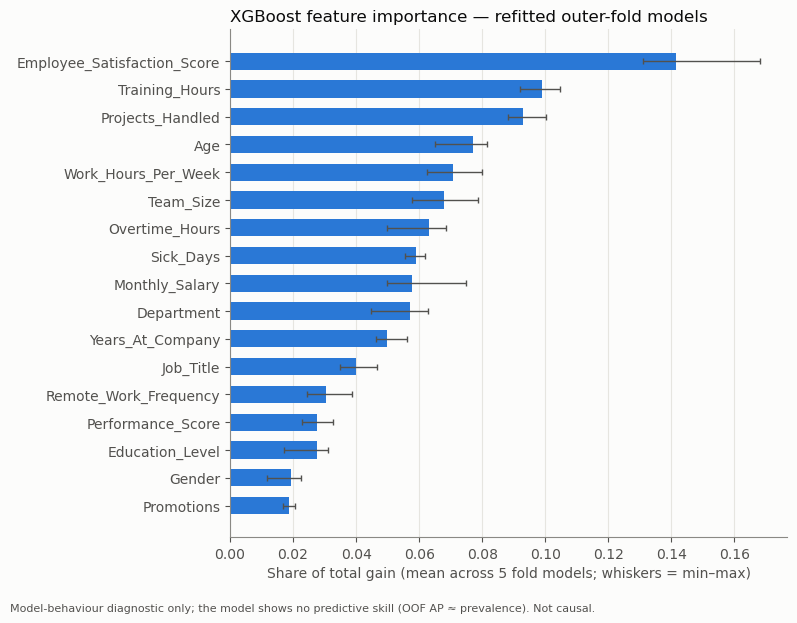

In [26]:
importance_rows = []
for fold, a in enumerate(fold_adapters, start=1):
    fi = a.feature_importances("total_gain")
    per_feature = fi.groupby("original_feature")["importance"].sum()
    total = per_feature.sum()
    for feature in feature_cols:
        gain = float(per_feature.get(feature, 0.0))
        importance_rows.append(
            {"fold": fold, "feature": feature, "total_gain": gain,
             "gain_share": gain / total if total > 0 else 0.0, "used_in_model": gain > 0}
        )
importance_long = pd.DataFrame(importance_rows)
importance_summary = (
    importance_long.groupby("feature")
    .agg(mean_gain_share=("gain_share", "mean"), sd_gain_share=("gain_share", "std"),
         min_gain_share=("gain_share", "min"), max_gain_share=("gain_share", "max"),
         folds_used=("used_in_model", "sum"))
    .sort_values("mean_gain_share", ascending=False)
    .reset_index()
)
feature_type = {c: "categorical" for c in categorical_cols} | {c: "numerical" for c in numerical_cols}
importance_summary.insert(1, "feature_type", importance_summary["feature"].map(feature_type))
importance_summary.to_csv(RESULTS_DIR / "feature_importance.csv", index=False)
importance_long.to_csv(RESULTS_DIR / "feature_importance_by_fold.csv", index=False)
display(importance_summary)

fig, ax = plt.subplots(figsize=(8, 6.2))
s = importance_summary.iloc[::-1]
ax.barh(s["feature"], s["mean_gain_share"], color=C_SERIES, height=0.62, zorder=2)
ax.errorbar(s["mean_gain_share"], s["feature"],
            xerr=[s["mean_gain_share"] - s["min_gain_share"], s["max_gain_share"] - s["mean_gain_share"]],
            fmt="none", ecolor=C_TEXT_2, elinewidth=1, capsize=2.5, zorder=3)
ax.set_xlabel("Share of total gain (mean across 5 fold models; whiskers = min–max)")
ax.grid(axis="y", visible=False)
ax.set_title("XGBoost feature importance — refitted outer-fold models", loc="left", fontsize=12, color=C_TEXT)
fig.text(0.01, 0.005, "Model-behaviour diagnostic only; the model shows no predictive skill (OOF AP ≈ prevalence). Not causal.",
         fontsize=8, color=C_TEXT_2)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(RESULTS_DIR / "figure_01_xgboost_feature_importance.png", dpi=200)
plt.show()

### 18.3 Precision–recall curves

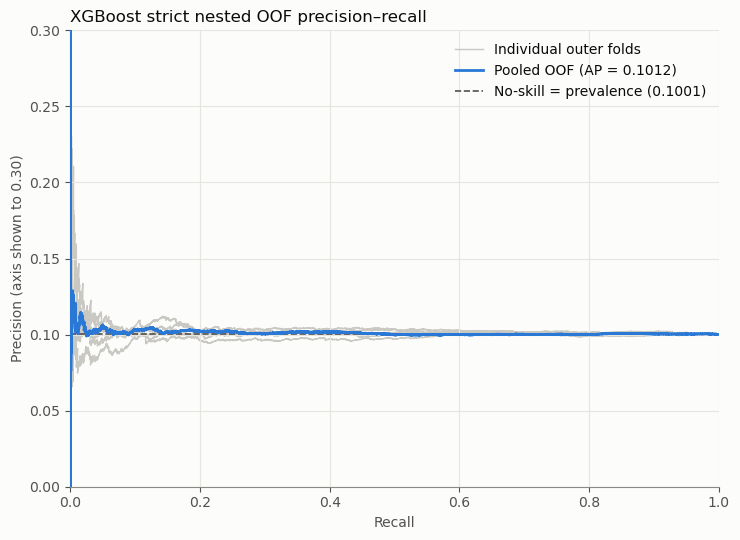

In [27]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for fold in range(1, 6):
    f = oof_out[oof_out["cv_fold"] == fold]
    p, r, _ = precision_recall_curve(f["y_true"], f["y_probability"])
    ax.plot(r, p, color=C_FOLD, lw=1, zorder=1, label="Individual outer folds" if fold == 1 else None)
p, r, _ = precision_recall_curve(oof_out["y_true"], oof_out["y_probability"])
ax.plot(r, p, color=C_SERIES, lw=2, zorder=3, label=f"Pooled OOF (AP = {pooled['average_precision']:.4f})")
ax.axhline(prevalence, color=C_TEXT_2, ls="--", lw=1.2, zorder=2, label=f"No-skill = prevalence ({prevalence:.4f})")
ax.set_xlim(0, 1)
ax.set_ylim(0, 0.30)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision (axis shown to 0.30)")
ax.set_title("XGBoost strict nested OOF precision–recall", loc="left", fontsize=12, color=C_TEXT)
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "figure_02_xgboost_pr_curve.png", dpi=200)
plt.show()

### 18.4 Confusion matrix at the 0.50 reference threshold

Pooled across folds. Four folds used class weighting and one did not, so the 0.50 threshold means something different per fold; per-fold counts are in `fold_metrics.csv`.

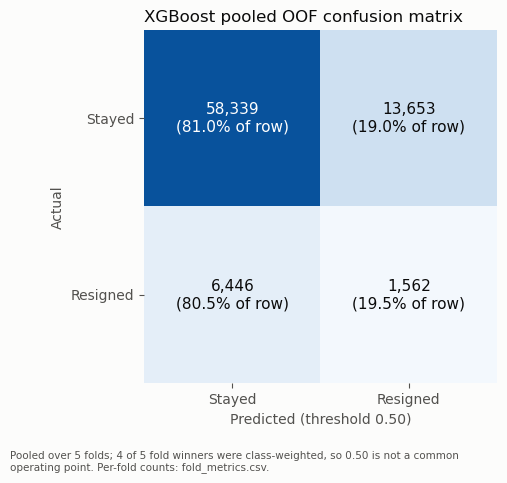

,Predicted: stayed,Predicted: resigned
Actual: stayed,58339,13653
Actual: resigned,6446,1562


In [28]:
cm = confusion_matrix(oof_out["y_true"], oof_out["y_pred_0_5"], labels=[0, 1])
cm_df = pd.DataFrame(cm, index=["Actual: stayed", "Actual: resigned"], columns=["Predicted: stayed", "Predicted: resigned"])
cm_df.to_csv(RESULTS_DIR / "confusion_matrix.csv")

fig, ax = plt.subplots(figsize=(5.8, 4.8))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max() * 1.15)
ax.grid(False)
for i in range(2):
    for j in range(2):
        share = cm[i, j] / cm[i].sum()
        ax.text(j, i, f"{cm[i, j]:,}\n({share:.1%} of row)", ha="center", va="center",
                color="#ffffff" if cm[i, j] > cm.max() * 0.55 else C_TEXT, fontsize=11)
ax.set_xticks([0, 1], ["Stayed", "Resigned"])
ax.set_yticks([0, 1], ["Stayed", "Resigned"])
ax.set_xlabel("Predicted (threshold 0.50)")
ax.set_ylabel("Actual")
ax.set_title("XGBoost pooled OOF confusion matrix", loc="left", fontsize=12, color=C_TEXT)
for spine in ax.spines.values():
    spine.set_visible(False)
fig.text(0.01, 0.01, "Pooled over 5 folds; 4 of 5 fold winners were class-weighted, so 0.50 is not a common\noperating point. Per-fold counts: fold_metrics.csv.", fontsize=7.5, color=C_TEXT_2)
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(RESULTS_DIR / "figure_03_xgboost_confusion_matrix.png", dpi=200)
plt.show()
display(cm_df)

### 18.5 OOF probability distribution by fold

Shows the calibration issue from Section 14: folds whose winner used `dynamic_ratio` weighting produce probabilities centred near 0.4–0.5, while the unweighted fold stays near the ~10% prevalence.

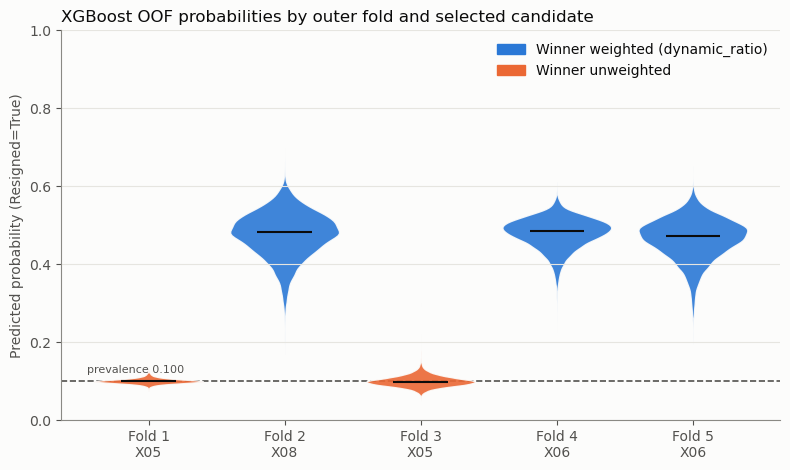

In [29]:
fig, ax = plt.subplots(figsize=(8, 4.8))
positions = np.arange(1, 6)
for fold in positions:
    probs = oof_out.loc[oof_out["cv_fold"] == fold, "y_probability"].to_numpy()
    weighted = fold_selection.loc[fold - 1, "weighting"] == "dynamic_ratio"
    parts = ax.violinplot(probs, positions=[fold], widths=0.8, showextrema=False, showmedians=True)
    for body in parts["bodies"]:
        body.set_facecolor(C_SERIES if weighted else C_SERIES_2)
        body.set_edgecolor(C_SURFACE)
        body.set_alpha(0.9)
    parts["cmedians"].set_color(C_TEXT)
ax.axhline(prevalence, color=C_TEXT_2, ls="--", lw=1.2, zorder=0)
ax.text(0.55, prevalence + 0.015, f"prevalence {prevalence:.3f}", va="bottom", fontsize=8, color=C_TEXT_2)
for fold in positions:
    probs = oof_out.loc[oof_out["cv_fold"] == fold, "y_probability"].to_numpy()
    if probs.max() - probs.min() < 0.05:  # too concentrated to see as a violin
        ax.plot([fold - 0.3, fold + 0.3], [np.median(probs)] * 2, color=C_SERIES_2, lw=4, solid_capstyle="round", zorder=3)
        ax.annotate(f"all values {probs.min():.3f}–{probs.max():.3f}", xy=(fold, np.median(probs)),
                    xytext=(fold, 0.25), ha="center", fontsize=8, color=C_TEXT_2,
                    arrowprops=dict(arrowstyle="-", color=C_TEXT_2, lw=0.8))
ax.set_xticks(positions, [f"Fold {f}\n{fold_selection.loc[f - 1, 'selected_candidate']}" for f in positions])
ax.set_ylim(0, 1)
ax.set_ylabel("Predicted probability (Resigned=True)")
ax.grid(axis="x", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=C_SERIES, label="Winner weighted (dynamic_ratio)"),
                   Patch(color=C_SERIES_2, label="Winner unweighted")],
          frameon=False, loc="upper right")
ax.set_title("XGBoost OOF probabilities by outer fold and selected candidate", loc="left", fontsize=12, color=C_TEXT)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "figure_04_xgboost_oof_probability_distribution.png", dpi=200)
plt.show()

### 18.5b Preprocessing and tree-count comparison figures

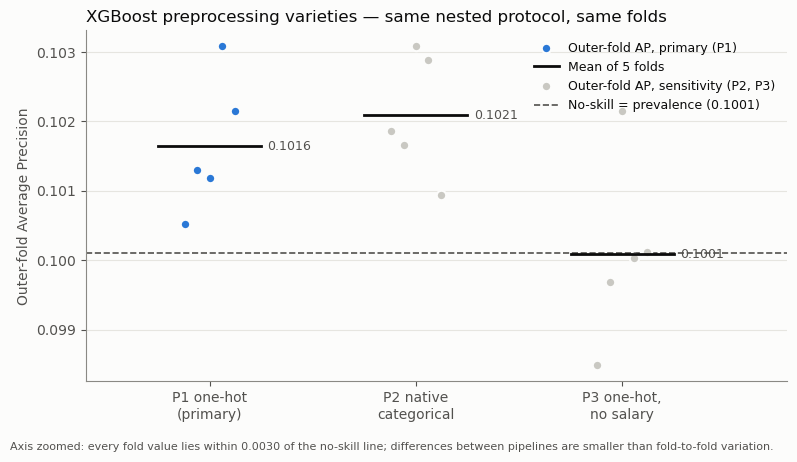

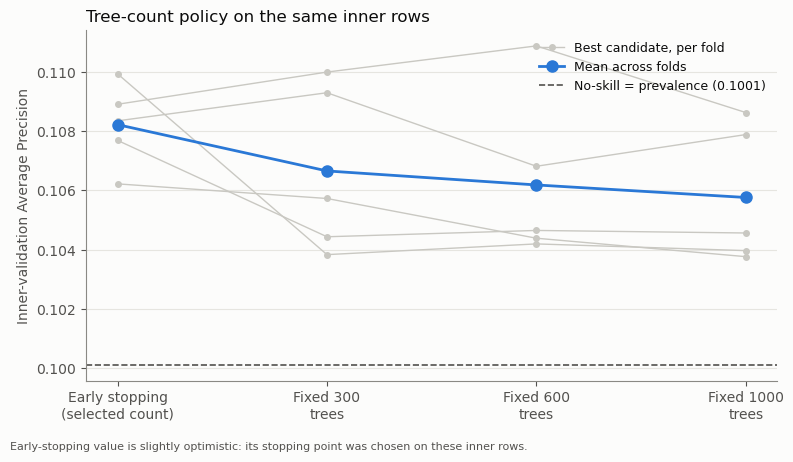

In [30]:
fig, ax = plt.subplots(figsize=(8, 4.6))
order = ["P1_onehot", "P2_native_categorical", "P3_onehot_no_salary"]
labels = ["P1 one-hot\n(primary)", "P2 native\ncategorical", "P3 one-hot,\nno salary"]
for i, v in enumerate(order):
    vals = variant_fold_metrics.loc[variant_fold_metrics["variant"] == v, "average_precision"].to_numpy()
    jitter = np.linspace(-0.12, 0.12, len(vals))
    ax.scatter(np.full(len(vals), i) + jitter, vals, s=46, color=C_SERIES if v == "P1_onehot" else C_FOLD,
               edgecolor=C_SURFACE, linewidth=1.5, zorder=3,
               label={0: "Outer-fold AP, primary (P1)", 1: "Outer-fold AP, sensitivity (P2, P3)"}.get(i))
    ax.plot([i - 0.25, i + 0.25], [vals.mean()] * 2, color=C_TEXT, lw=2, zorder=4,
            label="Mean of 5 folds" if i == 0 else None)
    ax.text(i + 0.28, vals.mean(), f"{vals.mean():.4f}", va="center", fontsize=9, color=C_TEXT_2)
ax.axhline(prevalence, color=C_TEXT_2, ls="--", lw=1.2, zorder=1, label=f"No-skill = prevalence ({prevalence:.4f})")
ax.set_xticks(range(len(order)), labels)
ax.set_ylabel("Outer-fold Average Precision")
ax.set_xlim(-0.6, len(order) - 0.2)
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper right", fontsize=9)
ax.set_title("XGBoost preprocessing varieties — same nested protocol, same folds", loc="left", fontsize=12, color=C_TEXT)
spread = float(np.abs(variant_fold_metrics["average_precision"] - prevalence).max())
fig.text(0.01, 0.01, f"Axis zoomed: every fold value lies within {spread:.4f} of the no-skill line; "
         "differences between pipelines are smaller than fold-to-fold variation.", fontsize=8, color=C_TEXT_2)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(RESULTS_DIR / "figure_05_xgboost_preprocessing_comparison.png", dpi=200)
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.6))
policy_labels = {"ap_early_stopped": "Early stopping\n(selected count)"} | {f"ap_{c}": f"Fixed {c}\ntrees" for c in checkpoints}
x = np.arange(len(policy_labels))
for fold in range(1, 6):
    best = [tree_count_table[tree_count_table["fold"] == fold][c].max() for c in policy_labels]
    ax.plot(x, best, color=C_FOLD, lw=1, marker="o", ms=4, zorder=2, label="Best candidate, per fold" if fold == 1 else None)
means = [tree_count_table.groupby("fold")[c].max().mean() for c in policy_labels]
ax.plot(x, means, color=C_SERIES, lw=2, marker="o", ms=8, zorder=3, label="Mean across folds")
ax.axhline(prevalence, color=C_TEXT_2, ls="--", lw=1.2, zorder=1, label=f"No-skill = prevalence ({prevalence:.4f})")
ax.set_xticks(x, list(policy_labels.values()))
ax.set_ylabel("Inner-validation Average Precision")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper right", fontsize=9)
ax.set_title("Tree-count policy on the same inner rows", loc="left", fontsize=12, color=C_TEXT)
fig.text(0.01, 0.01, "Early-stopping value is slightly optimistic: its stopping point was chosen on these inner rows.",
         fontsize=8, color=C_TEXT_2)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(RESULTS_DIR / "figure_06_xgboost_tree_count_policy.png", dpi=200)
plt.show()

### 18.6 Fold models: save and reload check (T-023)

In [31]:
reload_rows = []
runner_frame_ids = runner_frame.set_index(id_col)
for fold, a in enumerate(fold_adapters, start=1):
    fold_dir = MODELS_DIR / f"fold_{fold:02d}"
    a.save(fold_dir)
    restored = XGBoostAdapter.load(fold_dir)
    fold_rows = oof_out[oof_out["cv_fold"] == fold]
    X_fold = runner_frame_ids.loc[fold_rows["Employee_ID"], feature_cols]
    reproduced = restored.predict_proba(X_fold)
    identical = bool(np.array_equal(reproduced, fold_rows["y_probability"].to_numpy()))
    reload_rows.append({"fold": fold, "saved_to": str(fold_dir.relative_to(PROJECT_ROOT)),
                        "selected_candidate": restored.selected_candidate_id_, "predictions_identical": identical})
reload_check = pd.DataFrame(reload_rows)
display(reload_check)
assert reload_check["predictions_identical"].all(), "A reloaded fold model did not reproduce its OOF predictions."

,fold,saved_to,selected_candidate,predictions_identical
0,1,models\xgboost\fold_01,X05,True
1,2,models\xgboost\fold_02,X08,True
2,3,models\xgboost\fold_03,X05,True
3,4,models\xgboost\fold_04,X06,True
4,5,models\xgboost\fold_05,X06,True


### 18.7 Summary metrics and run provenance

In [32]:
dummy_prior = comparison.loc["Dummy Prior"]
models_trained = {
    "primary_inner_candidate_fits": int(len(selection_log)),
    "primary_outer_refits": int(len(fold_adapters)),
    "sensitivity_variant_fits": int(sum(preprocessing_comparison.loc[v, "models_trained"] for v in ["P2_native_categorical", "P3_onehot_no_salary"])),
    "tree_count_diagnostic_fits": int(len(tree_count_table)),
    "legacy_reproduction_fits": 5,
}
models_trained["total_xgboost_models_fitted"] = int(sum(models_trained.values()))
summary_out = {
    "result_label": "STRICT NESTED DEVELOPMENT OOF RESULTS",
    **oof_result.summary_metrics,
    "fold_mean_brier_score": float(fold_metrics_out["brier_score"].mean()),
    "fold_std_brier_score": float(fold_metrics_out["brier_score"].std()),
    "fold_mean_balanced_accuracy": float(fold_metrics_out["balanced_accuracy"].mean()),
    "development_prevalence": float(prevalence),
    "ap_lift_over_prevalence": float(pooled["average_precision"] / prevalence),
    "dummy_prior_average_precision": float(dummy_prior["average_precision"]),
    "dummy_prior_roc_auc": float(dummy_prior["roc_auc"]),
    "dummy_prior_brier_score": float(dummy_prior["brier_score"]),
    "label_shuffle_reference": {
        "repetitions": 1000, "seed": 2026,
        "ap_2_5_percentile": float(np.percentile(shuffled_ap, 2.5)),
        "ap_97_5_percentile": float(np.percentile(shuffled_ap, 97.5)),
        "share_of_shuffles_with_ap_ge_observed": share_ge,
    },
    "candidate_evaluations": int(len(selection_log)),
    "outer_winner_refits": int(len(fold_adapters)),
    "selected_candidates_by_fold": fold_selection["selected_candidate"].tolist(),
    "selected_trees_by_fold": fold_selection["selected_n_estimators"].astype(int).tolist(),
    "folds_with_weighted_winner": int((fold_selection["weighting"] == "dynamic_ratio").sum()),
    "winner_exceeded_random_inner_band_folds": int(inner_reference["winner_above_97.5%"].sum()),
    "threshold": 0.50,
    "formal_holdout_rows_used": 0,
    "primary_preprocessing_variant": "P1_onehot",
    "weighting_paired_inner_comparison": weighting_summary,
    "preprocessing_sensitivity": {
        v: {"fold_mean_ap": float(preprocessing_comparison.loc[v, "fold_mean_ap"]),
            "fold_sd_ap": float(preprocessing_comparison.loc[v, "fold_sd_ap"]),
            "pooled_ap": float(preprocessing_comparison.loc[v, "pooled_ap"]),
            "pooled_roc_auc": float(preprocessing_comparison.loc[v, "pooled_roc_auc"]),
            "pooled_brier": float(preprocessing_comparison.loc[v, "pooled_brier"]),
            "winners": preprocessing_comparison.loc[v, "winners"],
            "mean_ap_difference_vs_P1": (None if v == "P1_onehot" else float(paired_summary.loc[v, "mean"]))}
        for v in preprocessing_comparison.index
    },
    "tree_count_policy": {
        "early_stopped_tree_range": list(early_stopped_range),
        "share_stopped_below_min_checkpoint": share_below_300,
        "mean_best_inner_ap_by_policy": {k: float(v) for k, v in tree_policy_summary["winner_inner_ap_mean"].items()},
    },
    "legacy_exploratory_reproduction": {
        "reproduced_exactly": legacy_reproduces,
        "reproduced_pooled_ap": legacy_pooled_ap,
        "archived_pooled_ap": 0.1026,
        "max_abs_fold_ap_difference": float(legacy_reproduction["ap_difference"].abs().max()),
    },
    "models_trained": models_trained,
}
write_json(summary_out, RESULTS_DIR / "summary_metrics.json")

def git_state() -> dict:
    try:
        commit = subprocess.run(["git", "rev-parse", "HEAD"], cwd=PROJECT_ROOT, capture_output=True, text=True, check=True).stdout.strip()
        dirty = subprocess.run(["git", "status", "--porcelain", "--", "src", "configs", "notebooks/07_member_3", "tests/test_xgboost_adapter.py"],
                               cwd=PROJECT_ROOT, capture_output=True, text=True, check=True).stdout.strip()
        return {"git_commit": commit, "uncommitted_xgboost_changes": bool(dirty)}
    except Exception:
        return {"git_commit": None, "uncommitted_xgboost_changes": None,
                "git_note": "Not run inside a git checkout; code is identified by the source SHA-256 hashes below."}

source_files = {
    "configs/models/xgboost.yaml": PROJECT_ROOT / "configs" / "models" / "xgboost.yaml",
    "src/models/xgboost_model.py": PROJECT_ROOT / "src" / "models" / "xgboost_model.py",
    "src/models/runner.py": PROJECT_ROOT / "src" / "models" / "runner.py",
    "src/models/config.py": PROJECT_ROOT / "src" / "models" / "config.py",
    "src/evaluation/metrics.py": PROJECT_ROOT / "src" / "evaluation" / "metrics.py",
    "src/evaluation/oof_validation.py": PROJECT_ROOT / "src" / "evaluation" / "oof_validation.py",
    "configs/feature_contract.yaml": FEATURE_CONTRACT_PATH,
}
run_metadata = {
    "result_label": "STRICT NESTED DEVELOPMENT OOF RESULTS",
    "protocol": "five-fold strict nested cross-validation (outer CV / inner selection)",
    "model": "XGBoost",
    "member": "Member 3",
    "config_version": xgb_config["model"]["config_version"],
    "project_context_version": xgb_config["model"].get("project_context_version"),
    "run_finished_utc": run_finished_utc,
    **git_state(),
    "raw_dataset_sha256_lf_normalized": sha256_lf(DATA_PATH),
    "raw_dataset_sha256_file_bytes": sha256_of(DATA_PATH),
    "split_registry_sha256_lf_normalized": sha256_lf(SPLIT_PATH),
    "split_registry_sha256_expected": EXPECTED_SPLIT_SHA256,
    "split_registry_verified_before_training": True,
    "split_registry_sha256_file_bytes": sha256_of(SPLIT_PATH),
    "source_sha256": {k: sha256_of(v) for k, v in source_files.items()},
    "environment": environment,
    "seed": xgb_config["reproducibility"]["random_seed"],
    "candidate_ids": [c["id"] for c in xgb_config["candidates"]],
    "candidate_cap": xgb_config["search_budget"]["max_candidates"],
    "selection_metric": "inner-validation average precision (sklearn); ties -> earlier candidate",
    "early_stopping": {"monitor": xgb_config["fixed_params"]["eval_metric"],
                       "rounds": xgb_config["inner_validation"]["early_stopping_rounds"],
                       "max_boosting_rounds": xgb_config["inner_validation"]["max_boosting_rounds"]},
    "class_weighting": "per-candidate; dynamic_ratio = n_neg/n_pos from the rows being fitted only",
    "preprocessing": "fold-local OneHotEncoder(handle_unknown='ignore') on 4 categoricals; 13 numericals unscaled",
    "preprocessing_variants": {v["id"]: {k: v[k] for k in ("role", "encoding", "drop_features")}
                               for v in xgb_config["preprocessing_variants"]["variants"]},
    "tree_count_policy": xgb_config["tree_count_policy"],
    "models_trained": models_trained,
    "feature_count": len(feature_cols),
    "categorical_feature_count": len(categorical_cols),
    "numerical_feature_count": len(numerical_cols),
    "excluded_from_x": [id_col, "Hire_Date", target_col],
    "development_rows": int(len(dev_df)),
    "formal_holdout_rows": int(len(holdout_ids)),
    "formal_holdout_rows_used": 0,
    "outer_folds": 5,
    "outer_training_rows_per_fold": 64000,
    "outer_validation_rows_per_fold": 16000,
    "inner_training_rows_per_fold": int(len(fold_adapters[0].inner_training_index_)),
    "inner_validation_rows_per_fold": int(len(fold_adapters[0].inner_validation_index_)),
    "candidate_evaluations": int(len(selection_log)),
    "outer_winner_refits": int(len(fold_adapters)),
    "refit_on_all_outer_training_rows": bool(all(a.get_metadata()["fitted_on_all_outer_rows"] for a in fold_adapters)),
    "fold_models_saved_to": "models/xgboost/fold_01..fold_05 (git-ignored)",
    "fold_model_reload_reproduces_oof": bool(reload_check["predictions_identical"].all()),
    "wall_time_seconds": float(wall_time),
    "supersedes": "results/models/xgboost/exploratory_fixed_param_run/ (fixed parameters, global scale_pos_weight)",
}
write_json(run_metadata, RESULTS_DIR / "run_metadata.json")
print(json.dumps({k: run_metadata[k] for k in ("run_finished_utc", "git_commit", "raw_dataset_sha256_lf_normalized",
                                                "candidate_evaluations", "outer_winner_refits", "formal_holdout_rows_used")}, indent=2))

{
  "run_finished_utc": "2026-10-02T09:16:26+00:00",
  "git_commit": "e84be4e66d8d0430622db87d4bad178ee8b03037",
  "raw_dataset_sha256_lf_normalized": "2b1e07caf58e7678a780d428c1a8893a95d9c4a556134fd8e7368db5ed596cdb",
  "candidate_evaluations": 40,
  "outer_winner_refits": 5,
  "formal_holdout_rows_used": 0
}


### 18.8 Output manifest and final verification

Every saved file is re-read from disk and checked: the OOF file is re-validated with the shared validator, the summary is re-derived from the saved OOF file, and every artifact is listed with its SHA-256.

In [33]:
roles = {
    "oof_predictions.csv": "formal_oof_predictions",
    "fold_metrics.csv": "formal_fold_metrics",
    "summary_metrics.json": "formal_summary_metrics",
    "fold_selection.csv": "formal_fold_selection",
    "candidate_selection.csv": "formal_inner_candidate_evidence",
    "runtime_efficiency.csv": "formal_runtime_evidence",
    "feature_importance.csv": "feature_importance_summary",
    "feature_importance_by_fold.csv": "feature_importance_by_fold",
    "confusion_matrix.csv": "pooled_confusion_matrix_0_50",
    "run_metadata.json": "formal_run_provenance",
    "figure_01_xgboost_feature_importance.png": "figure_feature_importance",
    "figure_02_xgboost_pr_curve.png": "figure_precision_recall",
    "figure_03_xgboost_confusion_matrix.png": "figure_confusion_matrix",
    "figure_04_xgboost_oof_probability_distribution.png": "figure_probability_distribution",
    "weighting_paired_comparison.csv": "inner_weighting_paired_evidence",
    "preprocessing_comparison.csv": "preprocessing_sensitivity_summary",
    "preprocessing_fold_metrics.csv": "preprocessing_sensitivity_fold_metrics",
    "tree_count_diagnostic.csv": "tree_count_policy_diagnostic",
    "legacy_reproduction.csv": "superseded_run_reproduction_check",
    "figure_05_xgboost_preprocessing_comparison.png": "figure_preprocessing_comparison",
    "figure_06_xgboost_tree_count_policy.png": "figure_tree_count_policy",
}
for vf in variant_files:
    roles[str(vf.relative_to(RESULTS_DIR)).replace("\\", "/")] = f"sensitivity_{vf.parent.name}_{vf.stem}"
manifest = pd.DataFrame(
    [
        {"artifact": f"results/models/xgboost/{name}", "exists": (RESULTS_DIR / name).exists(),
         "size_bytes": (RESULTS_DIR / name).stat().st_size, "sha256": sha256_of(RESULTS_DIR / name), "role": role}
        for name, role in roles.items()
    ]
)
manifest.to_csv(RESULTS_DIR / "output_manifest.csv", index=False)
assert manifest["exists"].all()

# Re-read and verify the saved OOF file.
saved_oof = pd.read_csv(RESULTS_DIR / "oof_predictions.csv")
validate_oof_predictions(predictions=saved_oof, split_registry=split_registry, source_data=dev_df, expected_model_name="XGBoost")
assert list(saved_oof.columns) == ["Employee_ID", "cv_fold", "y_true", "model_name", "y_probability", "y_pred_0_5"]
assert len(saved_oof) == 80_000 and not set(saved_oof[id_col]) & holdout_ids
saved_summary = json.loads((RESULTS_DIR / "summary_metrics.json").read_text(encoding="utf-8"))
recomputed_ap = average_precision_score(saved_oof["y_true"], saved_oof["y_probability"])
assert abs(recomputed_ap - saved_summary["pooled_average_precision"]) < 1e-9
assert len(pd.read_csv(RESULTS_DIR / "candidate_selection.csv")) == 40
for vf in variant_files:
    if vf.name == "oof_predictions.csv":
        validate_oof_predictions(predictions=pd.read_csv(vf), split_registry=split_registry,
                                 source_data=dev_df, expected_model_name="XGBoost")

display(manifest[["artifact", "size_bytes", "role"]])
print(f"Verified {len(manifest)} artifacts. Saved OOF re-validated; pooled AP re-derived from disk = {recomputed_ap:.5f}.")

,artifact,size_bytes,role
0,results/models/xgboost/oof_predictions.csv,3228776,formal_oof_predictions
1,results/models/xgboost/fold_metrics.csv,1469,formal_fold_metrics
2,results/models/xgboost/summary_metrics.json,4215,formal_summary_metrics
3,results/models/xgboost/fold_selection.csv,798,formal_fold_selection
4,results/models/xgboost/candidate_selection.csv,11227,formal_inner_candidate_evidence
5,results/models/xgboost/runtime_efficiency.csv,561,formal_runtime_evidence
6,results/models/xgboost/feature_importance.csv,1949,feature_importance_summary
7,results/models/xgboost/feature_importance_by_f...,5123,feature_importance_by_fold
8,results/models/xgboost/confusion_matrix.csv,96,pooled_confusion_matrix_0_50
9,results/models/xgboost/run_metadata.json,4358,formal_run_provenance


Verified 27 artifacts. Saved OOF re-validated; pooled AP re-derived from disk = 0.10118.


## 19. Individual assessment checklist (Progress Review II)

This section maps the notebook to the individual requirements so each point can be shown during the viva.

**Model suitability.** The data is a 100,000-row table of 13 numerical and 4 nominal predictors with a 10% positive class. Gradient-boosted trees suit this: they capture non-linear effects and interactions without feature scaling, handle one-hot or native categorical inputs, regularise with depth, `min_child_weight`, subsampling and an L2 penalty, and offer `scale_pos_weight` for imbalance. XGBoost's histogram method trains 80 models per pipeline in seconds on a CPU. A suitable model cannot create signal that the features do not contain (Section 17).

**Implementation.** `xgboost.XGBClassifier` (objective `binary:logistic`, `tree_method="hist"`), wrapped in `src/models/xgboost_model.py::XGBoostAdapter` (`fit`, `predict_proba`, `tree_count_profile`, `feature_importances`, `save`/`load`). scikit-learn provides `OneHotEncoder`, `train_test_split` (stratified inner split) and the metrics; the shared `run_5fold_cv`, `validate_oof_predictions` and `calculate_binary_metrics` provide the outer loop, integrity checks and metric definitions. Hyperparameters are in Section 7 and `configs/models/xgboost.yaml`.

**Tuning method.** A bounded manual grid (8 candidates drawn from the canonical Section 8.21.5 values) evaluated by nested hold-out: inside each outer training fold, a stratified 15% inner split scores every candidate, and early stopping on that split sets the tree count. This plays the role of `GridSearchCV`, but nesting it inside the outer folds keeps the reported outer-fold score free of tuning bias; running `GridSearchCV` on all 80,000 rows and reporting its best score would be optimistic.

**Validation method.** Five frozen stratified outer folds from the shared split registry (checksum-verified, Section 3), each 64,000 training / 16,000 prediction-only rows; inner 85/15 stratified split inside each training fold; the 20% formal holdout never loaded.

**Metrics and why.** Average Precision is primary because only 10% of records are positive, and AP measures how well positives are ranked first (no-skill AP = prevalence). ROC-AUC is a secondary ranking measure; the Brier score measures probability quality, which matters because probabilities feed the later prioritisation; precision, recall, F1 and balanced accuracy at 0.50 describe one operating point. Accuracy is reported only with a warning: predicting "stays" for everyone scores 90%.

**Limitations and improvements.** (1) No usable signal, so tuning cannot help. (2) Class-weighted winners give poorly calibrated probabilities; calibration belongs in Notebook 12. (3) A single 15% inner split makes selection noisy; repeated inner folds would stabilise it, at roughly 5× the cost. (4) Results can differ slightly across XGBoost versions and CPUs, so the environment is recorded. (5) Feature importances describe model behaviour, not causes. (6) Different data (for example, engagement history or exit-survey features) would be needed before any further modelling is worthwhile.

In [34]:
checklist = pd.DataFrame([
    ("Model implemented", "XGBClassifier via XGBoostAdapter", "Sections 7-8; src/models/xgboost_model.py"),
    ("Hyperparameter varieties", f"{len(xgb_config['candidates'])} candidates x 5 folds = {len(selection_log)} inner evaluations", "Sections 7, 9"),
    ("Preprocessing varieties", f"{len(variant_runs)} pipelines (P1 primary, P2/P3 sensitivity)", "Section 14"),
    ("Tree-count varieties", f"early stopping vs fixed {', '.join(map(str, checkpoints))} ({len(tree_count_table) * len(checkpoints)} scored)", "Section 15"),
    ("Total XGBoost models fitted", str(models_trained["total_xgboost_models_fitted"]), "Section 18.7"),
    ("Tuning method", "bounded grid + early stopping, nested inside outer folds", "Sections 1, 9"),
    ("Validation", "5 frozen stratified outer folds; 15% inner split; holdout untouched", "Sections 3, 5, 10"),
    ("Primary metric", f"Average Precision: P1 fold mean {preprocessing_comparison.loc['P1_onehot', 'fold_mean_ap']:.4f} vs no-skill {prevalence:.4f}", "Sections 11-13"),
    ("Comparison and conclusion", "no variety exceeds chance; P1 kept as primary", "Sections 14-17"),
    ("Limitations and improvements", "calibration, inner-selection noise, no signal", "Section 19 text"),
], columns=["Requirement", "Evidence", "Where"])
display(checklist)

,Requirement,Evidence,Where
0,Model implemented,XGBClassifier via XGBoostAdapter,Sections 7-8; src/models/xgboost_model.py
1,Hyperparameter varieties,8 candidates x 5 folds = 40 inner evaluations,"Sections 7, 9"
2,Preprocessing varieties,"3 pipelines (P1 primary, P2/P3 sensitivity)",Section 14
3,Tree-count varieties,"early stopping vs fixed 300, 600, 1000 (120 sc...",Section 15
4,Total XGBoost models fitted,180,Section 18.7
5,Tuning method,"bounded grid + early stopping, nested inside o...","Sections 1, 9"
6,Validation,5 frozen stratified outer folds; 15% inner spl...,"Sections 3, 5, 10"
7,Primary metric,Average Precision: P1 fold mean 0.1016 vs no-s...,Sections 11-13
8,Comparison and conclusion,no variety exceeds chance; P1 kept as primary,Sections 14-17
9,Limitations and improvements,"calibration, inner-selection noise, no signal",Section 19 text


## 20. Readiness

- **Protocol-complete development evidence:** 80,000 OOF predictions for the primary pipeline (P1), from 40 inner candidate evaluations and 5 outer refits; no outer-validation or holdout rows were used for selection, early stopping, weighting or encoding.
- **Ready for Notebook 11** through the standard `results/models/xgboost/oof_predictions.csv`. The sensitivity-variant files under `preprocessing_variants/` are not model-comparison inputs.
- **For Notebook 12** (calibration): most fold winners were class-weighted, so calibration must be assessed before any XGBoost probability is used for prioritisation.
- **Formal holdout:** untouched; locked until the whole development pipeline is frozen (Notebook 15).